In [2]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [3]:
import os

# TODO: Fill in the Google Drive path where you uploaded the lab materials
# Example: GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'Colab Notebooks/Lab materials 01-20210104'

GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'City_University/Deep_Reinforcement_Learning' 
GOOGLE_DRIVE_PATH = os.path.join('drive', 'My Drive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)
print(os.listdir(GOOGLE_DRIVE_PATH))

['discrete_space.py', '__pycache__', 'Experiments old', 'environment.py', 'environment_door_reward.py', 'Task02_old.ipynb', 'environment_reduced_6_6.py', 'environment_hostage_update.py', 'experiment1_best_param.pickle', 'experiment1_gridsearch.pickle', 'experiment2_gridsearch.pickle', 'experiment2_best_param.pickle', 'Task02_old2.ipynb', 'environment_reduced.py', 'advtask_gridsearch.pickle', 'model.py', 'dqn_agent.py', 'advtask_ablation.pickle', 'Task02.ipynb']


In [6]:
import sys
sys.path.append(GOOGLE_DRIVE_PATH)

In [7]:
import numpy as np
import pandas as pd
import torch
from torch import Tensor, nn
from torch.optim import Adam, Optimizer
from torch.utils.data import DataLoader
from torch.utils.data.dataset import IterableDataset
import time
from IPython.display import clear_output
import pickle

from dqn_agent import DQNAgent

import gym
import random
import torch
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
%matplotlib inline

# frozen-lake-ex4.py
import gym
#env = gym.make("FrozenLake-v0", is_slippery=False)
#env = gym.make("CartPole-v1")

#from environment import MapWalkingEnv
from environment_reduced import MapWalkingEnv
#from environment_reduced_key import MapWalkingEnv
#from environment_reduced_6_6 import MapWalkingEnv

In [ ]:
env = MapWalkingEnv(10,10)
state = env.reset()
env.display()

Safe zone(S): (0, 0)  - Agent start: (9, 6) Rows to S: 9 Columns to S: 6
Green: Agent at least 2 rows and 2 columns close to safe zone
Yellow: Agent at least 4 rows and 4 columns close to safe zone
Red: Agent more than 4 rows or 4 columns far from safe zone

S X M . . . . . . . 
. . . . . X . . M . 
. . . . . X . . X . 
X X . X X . X . X . 
. . X . X . X X X . 
. . M . X . . . M . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . M 
. . . . . . A X . . 



In [ ]:
state

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [ ]:
#Definition of states and actions

# S = ['A','B','C','D','E','F']
# A = ['A','B','C','D','E','F']

In [ ]:
ss = env.reset()
states_total = 16
data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
def encode(data, states_total):
    targets = np.array(data).reshape(-1)
    return np.eye(states_total)[targets]
m = encode(data,states_total)
s = m[ss]
print(s)

[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
MAX_ITERATIONS = 10
 
env = gym.make("FrozenLake-v0")
env.reset()
env.render()
for i in range(MAX_ITERATIONS):
    random_action = env.action_space.sample()
    new_state, reward, done, info = env.step(
       random_action)
    print(new_state)
    env.render()
    
    if done:
        break


SFFF
FHFH
FFFH
HFFG
1
  (Up)
SFFF
FHFH
FFFH
HFFG
2
  (Down)
SFFF
FHFH
FFFH
HFFG
2
  (Up)
SFFF
FHFH
FFFH
HFFG
6
  (Left)
SFFF
FHFH
FFFH
HFFG
7
  (Right)
SFFF
FHFH
FFFH
HFFG


In [ ]:
env.reset()

0

In [ ]:
env.reset()

array([ 1.18350981e-04,  1.40453386e+00,  1.19682625e-02, -2.83838421e-01,
       -1.30303975e-04, -2.71100202e-03,  0.00000000e+00,  0.00000000e+00],
      dtype=float32)

## DQN class

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DQNetwork(nn.Module):
    """Simple MLP network."""
    
    # Network initialisation
    def __init__(self, obs_size: int, hidden_size: int, n_actions: int, lr):
        """
        Args:
            obs_size: observation/state size of the environment
            n_actions: number of discrete actions available in the environment
            hidden_size: size of hidden layers
        """
        super().__init__()
        self.fc1 = nn.Linear(obs_size, hidden_size)   
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.out = nn.Linear(hidden_size, n_actions)
        
        self.optimizer = optim.Adam(self.parameters(),lr=lr)
        self.loss = nn.MSELoss()
        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

        
    # Forward propagation 
    def forward(self, state):
        x = state.flatten(start_dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        return x

In [ ]:
qnetwork_local = DQNetwork(state_size=16, hidden_size=4, action_size=4, seed=0, lr=0)

In [ ]:
from dqn_model import DeepQNetwork
qnetwork_local = DeepQNetwork(state_size=16, fc1_dim=4, fc2_dim=4, action_size=4, seed=0, lr=0)

In [ ]:
print("Action space: ", env.action_space)

Action space:  Discrete(4)


In [ ]:
torch.flatten(state,start_dim=1)

TypeError: flatten(): argument 'input' (position 1) must be Tensor, not int

In [ ]:
torch.flatten(torch.from_numpy(np.array(state)).float().unsqueeze(0),start_dim=0)

tensor([0.])

In [ ]:
env = gym.make('LunarLander-v2')
env.seed(0)
print('State shape: ', env.observation_space.shape)
print('Number of actions: ', env.action_space.n)

print(env.reset())

State shape:  (8,)
Number of actions:  4
[-5.9156417e-04  1.4134574e+00 -5.9935719e-02  1.1277095e-01
  6.9228926e-04  1.3576316e-02  0.0000000e+00  0.0000000e+00]


In [ ]:
env.reset()

array([ 0.0075161 ,  1.4044806 ,  0.7612664 , -0.2862266 , -0.0087023 ,
       -0.17243806,  0.        ,  0.        ], dtype=float32)

In [ ]:
agent = DQNAgent(state_size=16, hidden_size=64, action_size=4, seed=0, lr=0)

# watch an untrained agent
state = env.reset()

states_total = 16
data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
def encode(data, states_total):
    targets = np.array(data).reshape(-1)
    return np.eye(states_total)[targets]

for j in range(200):
    m = encode(data,states_total)
    s = m[state]
    action = agent.act(s)
    env.render()
    state, reward, done, _ = env.step(action)
    states_total = 16
    
    
    if done:
        break 
        
env.close()

TypeError: __init__() got an unexpected keyword argument 'hidden_size'

In [ ]:
agent = DQNAgent(state_size=16, fc1_dim=64, fc2_dim=64, action_size=4, seed=0, lr=0.001)

In [ ]:
batch = np.random.choice(20, 16, replace=False)
print(batch)
print(np.arange(16, dtype=np.int32))

[ 3 10 11  4  9 17 13  7  6  8 18  1 14 19  5  0]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]


In [ ]:
env.reset()
state_arr=np.zeros(state_size)
state_arr[state] = 1
state= np.reshape(state_arr, [1, state_size])

In [ ]:
env.reset()

0

In [ ]:
env.observation_space.n

16

In [ ]:
def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_size])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

In [ ]:
state=env.reset()

In [ ]:
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)

def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 

action_dim=env.action_space.n

# CartPole    
# agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

#FrozenLake
agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
                 action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)

#MapWalking
#agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
#                 action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)


def DQN(num_episodes=4000, mem_count=1000, epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.995):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_t (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    scores_averaged = []
    epsilon = epsilon_start                    # initialize epsilon
    
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#     elif isinstance(env.observation_space, gym.spaces.Box):
#         state_shape = env.observation_space.shape
#         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
#     action_dim=env.action_space.n
    
#     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

    
    for i_episode in range(1, num_episodes+1):
        state = env.reset()
        
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        state = encode_state(env, gym, state)
        #print(state)
        score = 0
        for t in range(mem_count):
            action = agent.select_action(state, epsilon)
            next_state, reward, done, _ = env.step(action)
            #m = encode(data,states_total)
            #next_state = m[next_state]
            next_state = encode_state(env, gym, next_state)
            
            
            agent.step(state, action, reward, next_state, done)
            state = next_state
            #print(next_state,state)
            score += reward
            if done:
                break 
                
        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)), end="")
        if i_episode % 100 == 0:
            scores_averaged.append(np.mean(scores_window))
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
        if np.mean(scores_window)>=200.0:
            print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
            torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
            break
    return scores, scores_averaged

scores, scores_averaged = DQN()

# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(scores_averaged))*100, scores_averaged)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

NameError: name 'env' is not defined

In [ ]:
env.s
state_a = np.array([env.s], copy=False)
print(state_a)
state_v = torch.tensor(state_a).to('cpu')
print(state_v)

[15]
tensor([15], dtype=torch.int32)


In [ ]:
self.action_size = action_size
self.memory = deque(maxlen=int(1e5))  
self.batch_size = batch_size
self.experience = namedtuple("Experience", field_names=["state", "action", "reward", "next_state", "done"])
self.seed = random.seed(seed)

def add(self, state, action, reward, next_state, done):
    """Add a new experience to memory."""
    e = self.experience(state, action, reward, next_state, done)
    self.memory.append(e)

0

In [ ]:
agent.qnetwork_local.fc1.weight.dtype

torch.float32

In [ ]:
x = torch.tensor([[1, 2, 3, 4]])
torch.unsqueeze(x,2).dim()

3

In [ ]:
x.shape

torch.Size([1, 4])

In [ ]:
torch.from_numpy(np.array(state)).float().unsqueeze(0).to('cpu')

NameError: name 'state' is not defined

In [ ]:
.detach().max(1)[0].unsqueeze(1)

## Double DQN

In [ ]:
def optimize_model(double = False):
    
    
        # Get max predicted Q values (for next states) from target model
        Q_targets_next = self.qnetwork_target(next_states).detach().max(1)[0].unsqueeze(1)
        # Compute Q targets for current states 
        Q_targets = rewards + (gamma * Q_targets_next * (1 - dones))

        # Get expected Q values from local model
        Q_expected = self.qnetwork_local(states).gather(1, actions)
		
		if ddqn:
			selected_actions = Q_target(non_final_next_states).max(1)[1].unsqueeze(1).detach()
			next_Q_values[non_final_mask] = self.qnetwork_target(non_final_next_states).gather(1, selected_actions).view(-1,).detach()
		else:
			next_Q_values[non_final_mask] = self.qnetwork_target(non_final_next_states).max(1)[0].detach()
		
        # Compute loss
        loss = F.mse_loss(Q_expected, Q_targets)
        
		# Minimize the loss
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # ------------------- update target network ------------------- #
        self.soft_update(self.qnetwork_local, self.qnetwork_target, TAU)     

In [ ]:
env

<TimeLimit<FrozenLakeEnv<FrozenLake-v0>>>

In [ ]:
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=0.001, gamma=0.995)
#agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)

def encode_state(env, gym, state):
    if isinstance(env.observation_space, gym.spaces.Discrete):
        state_dim=env.observation_space.n
        state_arr=np.zeros(state_dim)
        state_arr[state] = 1
        state = np.reshape(state_arr, [1, state_dim])
    #elif isinstance(env.observation_space, gym.spaces.Box):
    #    state_shape = env.observation_space.shape
    #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    return state

if isinstance(env.observation_space, gym.spaces.Discrete):
    state_dim=env.observation_space.n
elif isinstance(env.observation_space, gym.spaces.Box):
    state_shape = env.observation_space.shape
    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 

action_dim=env.action_space.n

# CartPole    
# agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

#FrozenLake
agent = DDQNAgent(state_size=state_dim, fc1_dim=4, fc2_dim=50, 
                 action_size=action_dim, seed=0, lr=0.001, gamma=0.995)


def DDQN(num_episodes=4000, mem_count=1000, epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.995):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_t (int): maximum number of timesteps per episode
        eps_start (float): starting value of epsilon, for epsilon-greedy action selection
        eps_end (float): minimum value of epsilon
        eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    scores = []                        # list containing scores from each episode
    scores_window = deque(maxlen=100)  # last 100 scores
    scores_averaged = []
    epsilon = epsilon_start                    # initialize epsilon
    
    for i_episode in range(1, num_episodes+1):
        state = env.reset()
        
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        state = encode_state(env, gym, state)
        #print(state)
        score = 0
        for t in range(mem_count):
            action = agent.select_action(state, epsilon)
            next_state, reward, done, _ = env.step(action)
            #m = encode(data,states_total)
            #next_state = m[next_state]
            next_state = encode_state(env, gym, next_state)
            
            
            agent.step(state, action, reward, next_state, done)
            state = next_state
            #print(next_state,state)
            score += reward
            if done:
                break 
                
        scores_window.append(score)       # save most recent score
        scores.append(score)              # save most recent score
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)), end="")
        if i_episode % 100 == 0:
            scores_averaged.append(np.mean(scores_window))
            print('\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
        if np.mean(scores_window)>=200.0:
            print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
            torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
            break
    return scores, scores_averaged

scores, scores_averaged = DDQN()

# plot the scores
fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(scores_averaged))*100, scores_averaged)
plt.ylabel('Score')
plt.xlabel('Episode #')
plt.show()

NameError: name 'env' is not defined

In [ ]:
## Our Environment

In [ ]:
#These are the key actions you can apply at states
action_dict = {
    0: 'up',
    1: 'down',
    2: 'right',
    3: 'left',
    4: 'pickup',
    5: 'dropoff',
    6: 'open'
}

#Colours for environment
color2num = dict(
    gray=30,
    red=31,
    green=32,
    yellow=33,
    blue=34,
    magenta=35,
    cyan=36,
    white=37,
    crimson=38,
)

#Function to surround string with certain colour codes
def colorise(string, color, bold=False, highlight=False):
    attr = []
    num = color2num[color]
    if highlight:
        num += 10
    attr.append(str(num))
    if bold:
        attr.append("1")
    attrs = ";".join(attr)
    return f"\x1b[{attrs}m{string}\x1b[0m"

# A function that counts the number of true values when the cumulative sum of n probabilities
#In an array is greater than a randomly generated number used in the step function




# Own Environment

In [ ]:
from environment import MapWalkingEnv
env = MapWalkingEnv(10,10)

In [ ]:
agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
                action_size=action_dim, seed=0, lr=0.005, gamma=0.99)


In [ ]:
# #agent = DQNAgent(state_size=4, fc1_dim=64, fc2_dim=64, action_size=2, seed=0, lr=5e-4, gamma=0.99)



# def encode_state(env, gym, state):
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#         state_arr=np.zeros(state_dim)
#         state_arr[state] = 1
#         state = np.reshape(state_arr, [1, state_dim])
#     #elif isinstance(env.observation_space, gym.spaces.Box):
#     #    state_shape = env.observation_space.shape
#     #    state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
#     elif env.__class__.__name__ == 'MapWalkingEnv':
#         state_dim=env.observation_space.n
#         state_arr=np.zeros(state_dim)
#         state_arr[state] = 1
#         state = np.reshape(state_arr, [1, state_dim])
#     return state


# env = MapWalkingEnv(10,10)
    

# if isinstance(env.observation_space, gym.spaces.Discrete):
#     state_dim = env.observation_space.n
# elif isinstance(env.observation_space, gym.spaces.Box):
#     state_shape = env.observation_space.shape
#     state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
# else:
#     state_dim = env.observation_space.n
    
# action_dim=env.action_space.n

# # CartPole    
# # agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
# #                 action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)

# #FrozenLake
# # agent = DQNAgent(state_size=state_dim, fc1_dim=16, fc2_dim=16, 
# #                  action_size=action_dim, seed=0, lr=0.0005, gamma=0.99)

# #MapWalking
# # agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
# #                 action_size=action_dim, seed=0, lr=0.005, gamma=0.9)

# #MapWalking
# agent = DQNAgent(state_size=state_dim, fc1_dim=50, fc2_dim=50, 
#                 action_size=action_dim, seed=0, lr=0.001, gamma=0.9)

# def DQN(num_episodes=100, max_timesteps=200, epsilon_start=0.5, epsilon_end=0.01, epsilon_decay=0.999, qtarget_update=5):
#     """Deep Q-Learning.
    
#     Params
#     ======
#         n_episodes (int): maximum number of training episodes
#         max_timesteps (int): maximum number of timesteps per episode
#         eps_start (float): starting value of epsilon, for epsilon-greedy action selection
#         eps_end (float): minimum value of epsilon
#         eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
#     """
#     scores = []                        # list containing scores from each episode
#     scores_window = deque(maxlen=100)  # last 100 scores
#     scores_averaged = []
#     epsilon = epsilon_start                    # initialize epsilon
    
# #     if isinstance(env.observation_space, gym.spaces.Discrete):
# #         state_dim=env.observation_space.n
# #     elif isinstance(env.observation_space, gym.spaces.Box):
# #         state_shape = env.observation_space.shape
# #         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
# #     action_dim=env.action_space.n
    
# #     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
# #                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)
    

#     env = MapWalkingEnv(10,10)
#     rewards = np.zeros([num_episodes,max_timesteps])
    
#     for i_episode in range(1, num_episodes+1):
#         state = env.reset()
        
#         #states_total = 16
#         #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
#         #def encode(data, states_total):
#         #    targets = np.array(data).reshape(-1)
#         #    return np.eye(states_total)[targets]
        
#         #m = encode(data,states_total)
#         #state = m[state]
#         #print(state)
        
#         #state = encode_state(env, gym, state)
        
#         #print(state)
#         score = 0
#         for t in range(max_timesteps):
#             valid_actions = env.valid_actions()
#             #print('Before',env.s,valid_actions)
#             action = agent.select_action(state, valid_actions, epsilon)
            
# #             if env.P[env.s][action] == []:
# #                 while env.P[env.s][action] == []:
# #                     action = agent.select_action(state, epsilon)        
#             #print('After',env.s, action, valid_actions)        
#             next_state, reward, done, _ = env.step(action)
#             #next_state = encode_state(env, gym, next_state)      
            
#             agent.step(state, action, reward, next_state, done)
#             rewards[i_episode-1][t] = reward
#             state = next_state
#             #print(next_state,state)
#             score += reward
#             if done:
#                 break 
#         # Update the target network, copying all weights and biases in DQN
#         if i_episode % qtarget_update == 0:
#             agent.update_target_network()    

#         scores_window.append(score)       # save most recent score
#         scores.append(score)              # save most recent score
#         epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
#         if i_episode % 10 == 0:
#             print('\rEpisode {}\tAverage Rewards: {:.2f}'.format(i_episode, np.mean(scores)), end="")
#             print('\tSum Rewards: {0:.2f}'.format(score))
# #         if i_episode % 100 == 0:
# #             scores_averaged.append(np.mean(scores_window))
# #             print('\n\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
# #         if np.mean(scores_window)>=200.0:
# #             print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
# #             torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
# #             break
#     return scores, scores_averaged, rewards

# start = time.time()
# rewards_total, rewards_averaged, rewards = DQN()
# end = time.time()
# print(end - start)
# # plot the scores
# fig = plt.figure()
# ax = fig.add_subplot(111)
# plt.plot(np.arange(len(rewards_averaged))*100, rewards_averaged)
# plt.ylabel('Score')
# plt.xlabel('Episode #')
# plt.show()

# 4 Last experiment (Dueling Double Deep Q Network With Prioritized Replay)

### Dueling Double Deep Q Network With Double Attention

In [ ]:
# def DQN(num_episodes, max_timesteps, epsilon_start, epsilon_end, epsilon_decay, qtarget_update,
#         fc1_dim, fc2_dim,learning_rate,gamma,loss_fun,conv,dueling):
#     """Deep Q-Learning.
    
#     Params
#     ======
#         n_episodes (int): maximum number of training episodes
#         max_timesteps (int): maximum number of timesteps per episode
#         eps_start (float): starting value of epsilon, for epsilon-greedy action selection
#         eps_end (float): minimum value of epsilon
#         eps_decay (float): multiplicative factor (per episode) for decreasing epsilon
#     """
#     rewards_total = []                        # list containing scores from each episode
#     rewards_window = deque(maxlen=10)  # last 100 scores
#     scores_averaged = []
#     epsilon = epsilon_start                    # initialize epsilon
    
# #     if isinstance(env.observation_space, gym.spaces.Discrete):
# #         state_dim=env.observation_space.n
# #     elif isinstance(env.observation_space, gym.spaces.Box):
# #         state_shape = env.observation_space.shape
# #         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
# #     action_dim=env.action_space.n
    
# #     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
# #                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)
    
    

#     env = MapWalkingEnv(10,10)
#     rewards = np.zeros([num_episodes,max_timesteps])
    
#     state_size_decoded = env.observation_space_decoded
#     action_size = env.action_space

#     agent = DQNAgent(state_size=state_size_decoded, fc1_dim=fc1_dim, fc2_dim=fc2_dim, fc3_dim=64, 
#                 action_size=action_size, seed=0, learning_rate=learning_rate, gamma=gamma, loss_fun=loss_fun,
#                 conv=conv,dueling=dueling)

    
#     for i_episode in range(1, num_episodes+1):
#         state = env.reset()
#         state_decoded = np.array([v for _,v in enumerate(env.decode(state))])
#         #states_total = 16
#         #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
#         #def encode(data, states_total):
#         #    targets = np.array(data).reshape(-1)
#         #    return np.eye(states_total)[targets]
        
#         #m = encode(data,states_total)
#         #state = m[state]
#         #print(state)
        
#         #state = encode_state(env, gym, state)
        
#         #print(state)
#         score = 0
#         for t in range(max_timesteps):
#             valid_actions = env.valid_actions()
#             #print('Before',env.s,valid_actions)
#             #action = agent.select_action(state, valid_actions, epsilon)        
#             action = agent.select_action(state_decoded, valid_actions, epsilon)              
#             next_state, reward, terminal, _ = env.step(action)
            
#             next_state_decoded = np.array([v for _,v in enumerate(env.decode(next_state))])
#             #agent.step(state, action, reward, next_state, terminal)
#             agent.step(state_decoded, action, reward, next_state_decoded, terminal)
#             rewards[i_episode-1][t] = reward
#             #state = next_state
#             state_decoded = next_state_decoded
#             #print(next_state,state)
#             score += reward
#             if terminal:
#                 break 
#         # Update the target network, copying all weights and biases in DQN
#         if i_episode % qtarget_update == 0:
#             agent.update_target_network()    

#         rewards_window.append(score)       # save most recent score
#         rewards_total.append(score)              # save most recent score
#         epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
#         if i_episode % 10 == 0:
#             print('\rEpisode {}\tAvgRds: {:.2f}'.format(i_episode, np.mean(rewards_window)), end="")
#             print('\tMaxRds: {0:.2f}'.format(np.max(rewards_window)), end="")
#             print('\tEps: {0:.2f}'.format(epsilon))
# #         if i_episode % 100 == 0:
# #             scores_averaged.append(np.mean(scores_window))
# #             print('\n\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(scores_window)))
# #         if np.mean(scores_window)>=200.0:
# #             print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(scores_window)))
# #             torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
# #             break
#     return rewards_total, rewards_window, rewards


# start = time.time()
# rewards_total, rewards_window, rewards = DQN(num_episodes=6000, max_timesteps=200, epsilon_start=1, 
#                                              epsilon_end=0.05, epsilon_decay=0.9996, qtarget_update=7,
#                                              fc1_dim=64, fc2_dim=64,learning_rate=0.0001, gamma=0.95,
#                                              loss_fun='mse',conv=False,dueling=True)
# end = time.time()
# print(end - start)
# # Plot the Rewards
# fig = plt.figure()
# ax = fig.add_subplot(111)
# plt.plot(np.arange(len(rewards_total)), rewards_total)
# plt.ylabel('Rewards')
# plt.xlabel('Episode #')
# plt.show()

In [ ]:
from copy import copy


def DQN(num_epochs, max_timesteps, epsilon_start, epsilon_end, epsilon_decay, qtarget_update,
        fc1_dim,fc2_dim,learning_rate,gamma,loss_fun,conv,ddqn,dueling,per):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_timesteps (int): maximum number of timesteps per episode
        epsilon_start (float): starting value of epsilon, for epsilon-greedy action selection
        epsilon_end (float): minimum value of epsilon
        epsilon_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    max_steps = max_timesteps
    i_steps = 0
    losses = []
    losses_epoch = []
    losses_avg = []
    rewards_total = []                                      # list containing rewards from each episode
    rewards_window = deque(maxlen=10)                       # last 10 rewards
    losses_window = deque(maxlen=10)                        # last 10 losses
    rewards = np.zeros([num_epochs,max_steps])              # Rewards for each timestep and epoch
    epsilon = epsilon_start                                 # initialize epsilon
    
    # Initialise the environment (Complex)
    #env = MapWalkingEnv(10,10)
    
    # Initialise the environment (Easy)
    env = MapWalkingEnv(6,6)
    
    state_size_decoded = env.observation_space_decoded
    action_size = env.action_space
    
    # Initialise agent based on hyperparameters
    agent = DQNAgent(state_size=state_size_decoded, fc1_dim=fc1_dim, fc2_dim=fc2_dim, fc3_dim=64, 
                action_size=action_size, seed=0, learning_rate=learning_rate, gamma=gamma, loss_fun=loss_fun,
                conv=conv,ddqn=ddqn,dueling=dueling,per=per)

    

    for i_epoch in range(1, num_epochs+1):
        state = env.reset()
        state_decoded = env.decode_grid(state) + np.random.rand(1,state_size_decoded)/100.0  #state = encode_state(env, gym, state)
        
        losses_step = []
        score = 0
        moves = 0
        status = 1
        k=0
        while (status == 1):
            valid_actions = [0,1,2,3] #env.valid_actions()
            action = agent.select_action(state_decoded, valid_actions, epsilon)              

            previous_obs = copy(state_decoded)
            next_state, reward, terminal, _ = env.step(action)

            next_state_decoded = env.decode_grid(next_state) + np.random.rand(1,state_size_decoded)/100.0
            #print('Decode',state,next_state,np.array([v for _,v in enumerate(env.decode(state))]),
            #      np.array([v for _,v in enumerate(env.decode(next_state))]))
            #agent.step(state, action, reward, next_state, terminal)
#             if previous_obs.all() == next_state_decoded.all():
#                 print('Equal')
#             else:
#                 print('Not Equal')
                
            agent.step(previous_obs, action, reward, next_state_decoded, terminal)

            rewards[i_epoch-1][moves] = reward

            #state = encode_state(env, gym, state)
            state_decoded = next_state_decoded
            
            score += reward
            
            moves+=1
            i_steps+=1

            # Update the target network, copying all weights and biases in DQN 
            # (600 timesteps or 3 epochs if each epoch has reached a maximum timesteps of 200)
            if i_steps % qtarget_update == 0:
                agent.update_target_network()
            
            #if reward == 100:
            #    print('Terminal')
            
            if terminal or (moves >= max_steps):
                status = 0
                
            losses_step.append(agent.losses)
            
        if len(agent.losses) > 0:
            losses.append(np.mean(losses_step))             # save last loss between the networks (for each epoch)    
        else:
            losses_avg.append(0)
            losses.append(0)
            
        rewards_window.append(score)                      # save most recent cumulative rewards (10 most recent epochs)
        rewards_total.append(score)                       # save most recent reward (accross all epochs)
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon
        
   
        if i_epoch % 10 == 0:
            print('\rEpoch {}'.format(i_epoch), end="")
            print('\tAvgRds: {0:.2f} '.format(np.mean(rewards_window)), end="")
            print('\tMaxRds: {0:.2f} '.format(np.max(rewards_window)), end="")
            print('\tLoss: {:.2f}'.format(losses[i_epoch-1]), end="")
            print('\tEps: {0:.2f}'.format(epsilon))
            losses_avg.append(losses)   # save most recent losses (10 most recent epochs)
            
        if np.mean(rewards_window) > 100.0:
            print('\nEnvironment solved in {:d} i_epoch!\tAverage Reward: {:.2f}'.format(i_epoch-10, np.mean(rewards_window)))
            torch.save(agent.q_network.state_dict(), 'checkpoint.pth')
            break
            
    losses_avg = np.array(losses_avg)
    losses = np.array(losses)
    return rewards_total, rewards_window, rewards, losses, agent.q_network


#start = time.time()
# rewards_total1, rewards_window1, rewards1, losses1 = DQN(num_epochs=4000, max_timesteps=128, epsilon_start=1, 
#                                              epsilon_end=0.1, epsilon_decay=0.9994, qtarget_update=1000,
#                                              fc1_dim=32, fc2_dim=32,learning_rate=0.001, gamma=0.9,
#                                              loss_fun='mse',conv=False,dueling=True,ddqn=True,per=False)
# # end = time.time()
# # #print(end - start)
# # # Plot the Rewards
# # fig = plt.figure()
# # ax = fig.add_subplot(111)
# # plt.plot(np.arange(len(rewards_total1)), rewards_total1)
# # plt.ylabel('Rewards')
# # plt.xlabel('Episode #')
# # plt.show()



# #start = time.time()
# rewards_total2, rewards_window2, rewards2, losses2 = DQN(num_epochs=4000, max_timesteps=128, epsilon_start=1, 
#                                              epsilon_end=0.1, epsilon_decay=0.9994, qtarget_update=1000,
#                                              fc1_dim=75, fc2_dim=50,learning_rate=0.001, gamma=0.9,
#                                              loss_fun='mse',conv=False,dueling=False,ddqn=True,per=True)
# # end = time.time()
# # #print(end - start)
# # # Plot the Rewards
# # fig = plt.figure()
# # ax = fig.add_subplot(111)
# # plt.plot(np.arange(len(rewards_total2)), rewards_total2)
# # plt.ylabel('Rewards')
# # plt.xlabel('Episode #')
# # plt.show()



Epoch 10	AvgRds: -93.20 	MaxRds: 86.00 	Loss: 0.00	Eps: 0.90
Epoch 20	AvgRds: -241.60 	MaxRds: -4.00 	Loss: 78.43	Eps: 0.82
Epoch 30	AvgRds: -98.50 	MaxRds: 98.00 	Loss: 77.35	Eps: 0.74
Epoch 40	AvgRds: -137.60 	MaxRds: 86.00 	Loss: 83.90	Eps: 0.67
Epoch 50	AvgRds: -151.20 	MaxRds: 100.00 	Loss: 90.58	Eps: 0.61
Epoch 60	AvgRds: -153.90 	MaxRds: 80.00 	Loss: 97.34	Eps: 0.55
Epoch 70	AvgRds: -201.80 	MaxRds: 99.00 	Loss: 102.14	Eps: 0.49
Epoch 80	AvgRds: -89.90 	MaxRds: 100.00 	Loss: 106.28	Eps: 0.45
Epoch 90	AvgRds: -148.50 	MaxRds: 100.00 	Loss: 109.25	Eps: 0.40
Epoch 100	AvgRds: -168.50 	MaxRds: 100.00 	Loss: 112.09	Eps: 0.37
Epoch 110	AvgRds: -169.90 	MaxRds: 99.00 	Loss: 115.53	Eps: 0.33
Epoch 120	AvgRds: -164.90 	MaxRds: 54.00 	Loss: 117.55	Eps: 0.30
Epoch 130	AvgRds: -165.30 	MaxRds: -116.00 	Loss: 118.93	Eps: 0.27
Epoch 140	AvgRds: -160.90 	MaxRds: -133.00 	Loss: 119.77	Eps: 0.24
Epoch 150	AvgRds: -173.20 	MaxRds: 100.00 	Loss: 119.89	Eps: 0.22
Epoch 160	AvgRds: -135.50 	MaxRds: 

Text(0, 0.5, 'Loss')

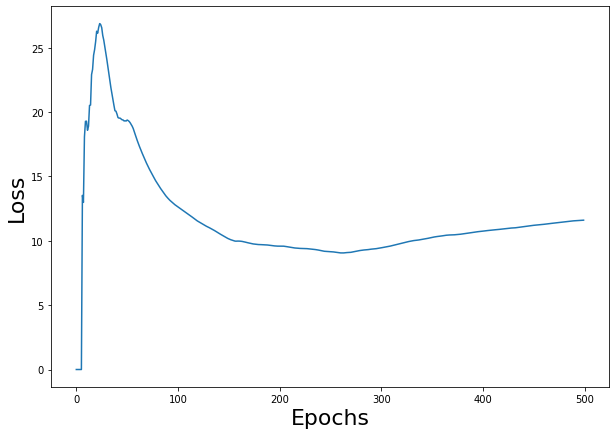

In [ ]:
plt.figure(figsize=(10,7))
plt.plot(losses3)
plt.xlabel("Epochs",fontsize=22)
plt.ylabel("Loss",fontsize=22)

In [ ]:
import copy

l1 = 400
l2 = 150
l3 = 100
l4 = 4

device = torch.device('cpu')
if torch.cuda.is_available():
    device = torch.device('cuda')

print(device)

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2),
    torch.nn.ReLU(),
    torch.nn.Linear(l2, l3),
    torch.nn.ReLU(),
    torch.nn.Linear(l3,l4)
).to(device)



net = nn.Sequential(
      nn.Linear(3, 4),
      nn.Sigmoid(),
      nn.Linear(4, 1),
      nn.Sigmoid()
      ).to(device)
model2 = copy.deepcopy(model) #A
model2.load_state_dict(model.state_dict()) #B

loss_fn = torch.nn.MSELoss()
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

gamma = 0.9
epsilon = 0.6

cuda


In [ ]:
env = MapWalkingEnv(10,10)
state = env.reset()
env.display()

Safe zone(S): (0, 0)  - Agent start: (9, 1) Rows to S: 9 Columns to S: 1
Green: Agent at least 2 rows and 2 columns close to safe zone
Yellow: Agent at least 4 rows and 4 columns close to safe zone
Red: Agent more than 4 rows or 4 columns far from safe zone

S X M . . . . . . . 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . . . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. A . . . . . X . . 



In [ ]:
a = np.random.rand(1,400)*10
a[0][1]

1.1966596746464442

In [ ]:
from collections import deque
epochs = 6000
losses = []
mem_size = 1000
batch_size = 200
replay = deque(maxlen=mem_size)
max_moves = 80
h = 0
sync_freq = 500 #A
j=0
for i in range(epochs):
    env = MapWalkingEnv(10,10)
    state = env.reset()
    state1_ = env.decode_grid(state) + np.random.rand(1,400)/100.0  #state = encode_state(env, gym, state)
        
    #state1_ = game.board.render_np().reshape(1,64) + np.random.rand(1,144)/100.0
    state1 = torch.from_numpy(state1_).float().to(device)
    status = 1
    mov = 0
    losses_ep = []
    while(status == 1): 
        j+=1
        mov += 1
        qval = model(state1)
        qval_ = qval.data.cpu().numpy()
        if (random.random() < epsilon):
            action_ = np.random.randint(0,4)
        else:
            action_ = np.argmax(qval_)
            
        #action = action_set[action_]
        action = action_
        #game.makeMove(action)
        next_state, reward, terminal, _ = env.step(action)

        state2_ = env.decode_grid(next_state) + np.random.rand(1,400)/100.0
        #state2_ = game.board.render_np().reshape(1,64) + np.random.rand(1,64)/100.0
        state2 = torch.from_numpy(state2_).float().to(device)
        #reward = game.reward()
        done = True if (reward == 100 or reward == -100) else False
        #print(j,state1, action_, reward, state2, done)
        exp =  (state1, action_, reward, state2, done)
        replay.append(exp) #H
        state1 = state2
        
        if len(replay) > batch_size:
            minibatch = random.sample(replay, batch_size)
            state1_batch = torch.cat([s1 for (s1,a,r,s2,d) in minibatch]).to(device)
            action_batch = torch.Tensor([a for (s1,a,r,s2,d) in minibatch]).to(device)
            reward_batch = torch.Tensor([r for (s1,a,r,s2,d) in minibatch]).to(device)
            state2_batch = torch.cat([s2 for (s1,a,r,s2,d) in minibatch]).to(device)
            done_batch = torch.Tensor([d for (s1,a,r,s2,d) in minibatch]).to(device)
            Q1 = model(state1_batch) 
            with torch.no_grad():
                Q2 = model2(state2_batch) #B
            
            Y = reward_batch + gamma * ((1-done_batch) * torch.max(Q2,dim=1)[0])
            X = Q1.gather(dim=1,index=action_batch.long().unsqueeze(dim=1)).squeeze()
            loss = loss_fn(X, Y.detach())
            print(i, loss.item())
            clear_output(wait=True)
            optimizer.zero_grad()
            loss.backward()
            #losses.append(loss.item())
            losses_ep.append(loss.item())
            optimizer.step()
            
            if j % sync_freq == 0: #C
                model2.load_state_dict(model.state_dict())
        
        #if (reward == 100 or reward == -100 or mov > max_moves):
        if (reward == 100 or reward == -100 or mov > max_moves):
            #print(reward)
            status = 0
            mov = 0
        
    losses.append(np.mean(losses_ep))
        
losses = np.array(losses)
 
#A Set the update frequency for synchronizing the target model parameters to the main DQN
#B Use the target network to get the maiximum Q-value for the next state
#C Copy the main model parameters to the target network

5999 0.38951316475868225


In [ ]:
min(X.detach().cpu().numpy())

-99.56842

In [ ]:

# def moving_avg(arr,w=50):
#     window_size = w
#     i = 0
#     # Initialize list to store moving avg
#     moving_avg = []

#     # Loop through the array to consider window size
#     while i < len(arr) - window_size + 1:
        
#         if i % window_size == 0:
#             # Store elements to get the current window
#             window = arr[i : i + window_size]

#             # Average of current window
#             window_avg = round(sum(window) / window_size, 2)

#             # Store the average of current
#             # window in moving average list
#             moving_avg.append(window_avg)

#         # Shift window to right by one position
#         i += 1

#     return moving_avg

# losses_epochs = moving_avg(losses,100)

In [182]:
from collections import deque
import copy

def DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma_val, eps, batch_size, mem_size, qtarget_update, eps_decay=1):


    input_dim = state_size
    fc1_dim = fc1 #150
    fc2_dim = fc2 #100
    output_dim = action_size #4

    # Set device
    device = torch.device('cpu')
    if torch.cuda.is_available():
        device = torch.device('cuda')

    #print(device)

    q_online_network = torch.nn.Sequential(
        torch.nn.Linear(input_dim, fc1_dim),
        torch.nn.ReLU(),
        torch.nn.Linear(fc1_dim, fc2_dim),
        torch.nn.ReLU(),
        torch.nn.Linear(fc2_dim,output_dim)
    ).to(device)

#     q_target_network = torch.nn.Sequential(
#         torch.nn.Linear(input_dim, fc1_dim),
#         torch.nn.ReLU(),
#         torch.nn.Linear(fc1_dim, fc2_dim),
#         torch.nn.ReLU(),
#         torch.nn.Linear(fc2_dim,output_dim)
#     ).to(device)


    q_target_network = nn.Sequential(
        nn.Linear(3, 4),
        nn.Sigmoid(),
        nn.Linear(4, 1),
        nn.Sigmoid()
        ).to(device)

    q_target_network = copy.deepcopy(q_online_network)  
    q_target_network.load_state_dict(q_online_network.state_dict())  

    loss_fn = torch.nn.MSELoss()
    learning_rate = lr #1e-3
    optimizer = torch.optim.Adam(q_online_network.parameters(), lr=learning_rate)

    gamma = gamma_val #0.9
    epsilon = eps #0.6
    epsilon_decay = eps_decay
    epsilon_end = 0.01
    
    num_epochs = epochs
    losses = []
    avg_qvalues_ep = []
    max_qvalues_ep = []
    cum_rewards = []
    reward_window = deque(maxlen=100) # last 100 rewards

    mem_size = mem_size #1000
    batch_size = batch_size #200
    replay = deque(maxlen=mem_size)
    max_moves = 80
    h = 0
    sync_freq = qtarget_update # 500 # Update target network every qtarget_update steps
    j=0

    # Initialise Environment
    env = MapWalkingEnv(10,10)

    for i in range(num_epochs):
        
        state = env.reset()
        state_ = env.decode_grid(state) + np.random.rand(1,400)/100.0  #state = encode_state(env, gym, state)
            
        #state1_ = game.board.render_np().reshape(1,64) + np.random.rand(1,144)/100.0
        state = torch.from_numpy(state_).float().to(device)
        status = 1
        mov = 0
        steps = 0
        cum_reward = 0
        max_qvalues = 0
        sum_qvalues = 0
        losses_ep = []
        while(status == 1): 
            j+=1
            mov += 1
            steps=+1
            qval = q_online_network(state)
            qval_ = qval.data.cpu().numpy()
            if (random.random() < epsilon):
                action_ = np.random.randint(0,4)
            else:
                action_ = np.argmax(qval_)
                
            #action = action_set[action_]
            action = action_
            #game.makeMove(action)
            next_state, reward, terminal, _ = env.step(action)

            next_state_ = env.decode_grid(next_state) + np.random.rand(1,400)/100.0
            #state2_ = game.board.render_np().reshape(1,64) + np.random.rand(1,64)/100.0
            next_state = torch.from_numpy(next_state_).float().to(device)
            #reward = game.reward()
            done = True if (reward == 100 or reward == -100) else False
            #print(j,state1, action_, reward, state2, done)
            exp =  (state, action_, reward, next_state, done)
            replay.append(exp) #H
            state = next_state
            
            if len(replay) > batch_size:
                minibatch = random.sample(replay, batch_size)
                state_batch = torch.cat([s1 for (s1,a,r,s2,d) in minibatch]).to(device)
                action_batch = torch.Tensor([a for (s1,a,r,s2,d) in minibatch]).to(device)
                reward_batch = torch.Tensor([r for (s1,a,r,s2,d) in minibatch]).to(device)
                next_state_batch = torch.cat([s2 for (s1,a,r,s2,d) in minibatch]).to(device)
                done_batch = torch.Tensor([d for (s1,a,r,s2,d) in minibatch]).to(device)
                Q1 = q_online_network(state_batch) 
                with torch.no_grad():
                    Q2 = q_target_network(next_state_batch) #B
                
                Y = reward_batch + gamma * ((1-done_batch) * torch.max(Q2,dim=1)[0])
                X = Q1.gather(dim=1,index=action_batch.long().unsqueeze(dim=1)).squeeze()
                loss = loss_fn(X, Y.detach())
                print(i, loss.item())
                clear_output(wait=True)
                optimizer.zero_grad()
                loss.backward()
                #losses.append(loss.item())
                losses_ep.append(loss.item())
                optimizer.step()
                
                if j % sync_freq == 0: #C
                    q_target_network.load_state_dict(q_online_network.state_dict())
                
                sum_qvalues += sum(X.detach().cpu().numpy())
                max_qvalues = max(max(X.detach().cpu().numpy()),max_qvalues)
            
            #print(reward)
            cum_reward += reward
            #if (reward == 100 or reward == -100 or mov > max_moves):
            if (reward == 100 or reward == -100 or mov > max_moves):
                #print(reward)
                status = 0
                mov = 0
        
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # decrease epsilon over time
        
        #print(cum_rewards)
        sum_qvalues_ep = sum_qvalues / steps

        losses.append(np.mean(losses_ep))
        reward_window.append(cum_reward)
        cum_rewards.append(cum_reward)
        avg_qvalues_ep.append(sum_qvalues_ep)
        max_qvalues_ep.append(max_qvalues)

        if np.mean(reward_window)>=200.0:
            print('\nEnvironment solved in {:d} episodes!\tAverage Reward: {:.2f}'.format(i-100, np.mean(reward_window)))
            torch.save(q_online_network.state_dict(), 'checkpoint.pth')
            break   
    losses = np.array(losses)
    return losses, cum_rewards, reward_window, avg_qvalues_ep, max_qvalues_ep, \
           lr, epsilon, gamma, epsilon, mem_size, batch_size, fc1, fc2, sync_freq #, q_online_network

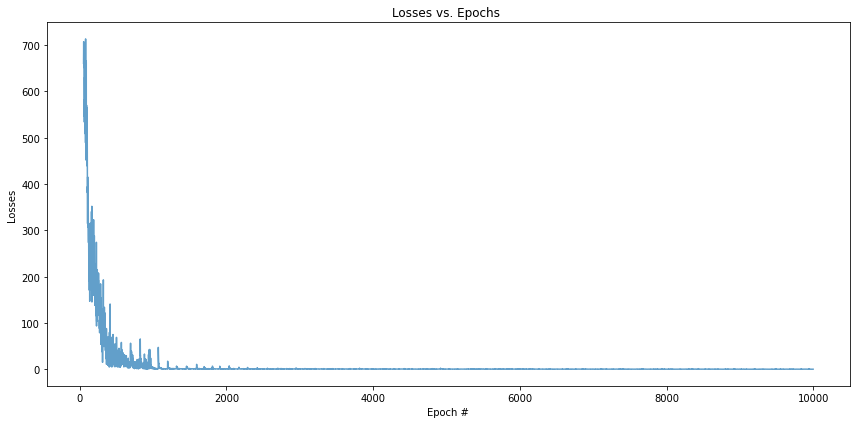

In [ ]:
# end = time.time()
# #print(end - start)
# Plot the Losses
fig = plt.figure(figsize=(12,6),tight_layout=True)
ax = fig.add_subplot(111)
plt.plot(np.arange(len(losses)), losses, alpha=0.7)
plt.title('Losses vs. Epochs ')
plt.ylabel('Losses')
plt.xlabel('Epoch #')
plt.show()

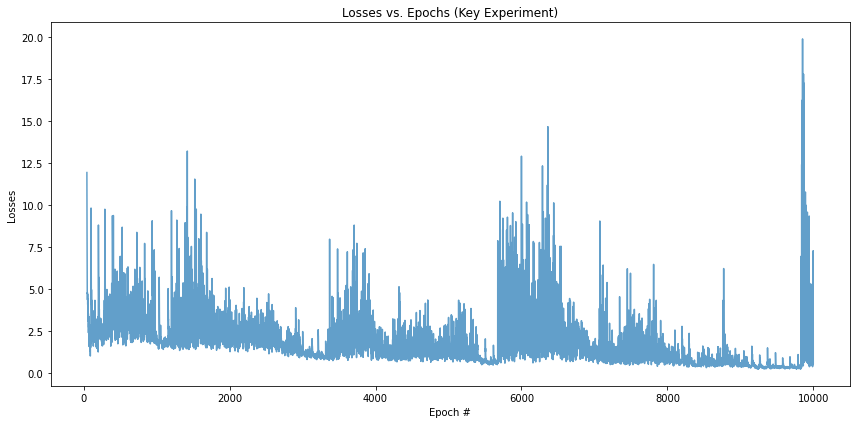

In [ ]:
# end = time.time()
# #print(end - start)
# Plot the Losses
fig = plt.figure(figsize=(12,6),tight_layout=True)
ax = fig.add_subplot(111)
plt.plot(np.arange(len(losses)), losses, alpha=0.7)
plt.title('Losses vs. Epochs (Key Experiment)')
plt.ylabel('Losses')
plt.xlabel('Epoch #')
plt.show()

## Random Search for Hyperparameter tuning

In [ ]:
We shall test the following hypothesis for the hyperparameter choice for the Vanilla DQN 16 different combinations

In [ ]:
Number of episodes fixed (6000)

4 changes:
hypothesis - batch size and neural network structure (changes in batch size for each direction and hidden layer structure)

batch_size = 128 vs batch_size = 256 (fc1 and fc2 fixed in 150, 100 respectively)
fc1 = 200 fc2 = 150 vs fc1 = 100 fc2 = 50 (batch size fixed in 200)

2 changes:
hypothesis - learning rate (changes for learning rate 1e-2 and 1e-4) 
(fc1 and fc2 fixed in 150, 100 respectively) and (batch size fixed in 200)

2 changes:
gamma: 0.8 and 0.95
gamma = 0.9 originally
all other baseline hyperparameters fixed

2 changes:
hypothesis - epsilon (changes for epsilon for 0.6 and 0.8) 
epsilon = 0.6 and 0.8
all other baseline hyperparameters fixed

2 changes:
hypothesis - synch frequency (changes for target network update set to 400 and 800) usually between 5 and 10 episodes based on max moves
all other baseline hyperparameters fixed

2 changes:
hypothesis - mem size (changes for mem size set to 2000 and 3000) we expect higher values to yield better results but still need evidence to prove
all other baseline  hyperparameters fixed

1 change:
hypothesis - changes in epsilon decay
all other baseline  hyperparameters fixed

1 change:
hypothesis - changes in gamma and epsilon decay
all other baseline  hyperparameters fixed

SyntaxError: ignored

In [ ]:
# Fixed baseline Vanilla DQN parameters
state_size=400 
fc1=150 
fc2=100 
action_size=4
epochs=2000
lr=1e-3 
gamma=0.9 
eps=0.6 
batch_size=200
mem_size=1000
qtarget_update=500

losses_target, cum_reward_target, rewards_window_target, avg_qvalues_ep_target, _, _, _, _, _, _, _, _, _, _ \
= DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, qtarget_update)

losses_notarget, cum_reward_notarget, rewards_window_notarget, avg_qvalues_ep_notarget, _, _, _, _, _, _, _, _, _, _ \
= DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, 1)

1999 0.34612205624580383


Executions

In [184]:
# Fixed baseline Vanilla DQN parameters
state_size=400 
fc1=150 
fc2=100 
action_size=4
epochs=6000
lr=1e-3 
gamma=0.9 
eps=0.6 
batch_size=200
mem_size=1000
qtarget_update=500

# losses_base2, cum_reward_base2, rewards_window_base2, avg_qvalues_ep_base2, max_qvalues_ep_base2, \
#            lr_base2, epsilon_base2, gamma_base2, epsilon_base2, mem_size_base2, batch_size_base2, fc1_base2, fc2_base2, sync_freq_base2, model \
# = DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, qtarget_update)

# 1) 
# losses_base, cum_reward_base, rewards_window_base, avg_qvalues_ep_base, max_qvalues_ep_base, \
#            lr_base, epsilon_base, gamma_base, epsilon_base, mem_size_base, batch_size_base, fc1_base, fc2_base, sync_freq_base = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, qtarget_update)

# 1) 
# losses_1, cum_reward_1, rewards_window_1, avg_qvalues_ep_1, max_qvalues_ep_1, \
#            lr_1, epsilon_1, gamma_1, epsilon_1, mem_size_1, batch_size_1, fc1_1, fc2_1, sync_freq_1 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, 128, mem_size, qtarget_update)


# # # 2) 
# losses_2, cum_reward_2, rewards_window_2, avg_qvalues_ep_2, max_qvalues_ep_2, \
#            lr_2, epsilon_2, gamma_2, epsilon_2, mem_size_2, batch_size_2, fc1_2, fc2_2, sync_freq_2 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, 256, mem_size, qtarget_update)


# # 3) 
# losses_3, cum_reward_3, rewards_window_3, avg_qvalues_ep_3, max_qvalues_ep_3, \
#            lr_3, epsilon_3, gamma_3, epsilon_3, mem_size_3, batch_size_3, fc1_3, fc2_3, sync_freq_3 = \
# DQN_Train(state_size, 200, 150, action_size, epochs, lr, gamma, eps, batch_size, mem_size, qtarget_update)


# # 4) 
# losses_4, cum_reward_4, rewards_window_4, avg_qvalues_ep_4, max_qvalues_ep_4, \
#            lr_4, epsilon_4, gamma_4, epsilon_4, mem_size_4, batch_size_4, fc1_4, fc2_4, sync_freq_4 = \
# DQN_Train(state_size, 100, 50, action_size, epochs, lr, gamma, eps, batch_size, mem_size, qtarget_update)


# # 5) 
# losses_5, cum_reward_5, rewards_window_5, avg_qvalues_ep_5, max_qvalues_ep_5, \
#            lr_5, epsilon_5, gamma_5, epsilon_5, mem_size_5, batch_size_5, fc1_5, fc2_5, sync_freq_5 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, 1e-2, gamma, eps, batch_size, mem_size, qtarget_update)


# # # 6) 
# losses_6, cum_reward_6, rewards_window_6, avg_qvalues_ep_6, max_qvalues_ep_6, \
#            lr_6, epsilon_6, gamma_6, epsilon_6, mem_size_6, batch_size_6, fc1_6, fc2_6, sync_freq_6 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, 1e-4, gamma, eps, batch_size, mem_size, qtarget_update)


# # 7) 
# losses_7, cum_reward_7, rewards_window_7, avg_qvalues_ep_7, max_qvalues_ep_7, \
#            lr_7, epsilon_7, gamma_7, epsilon_7, mem_size_7, batch_size_7, fc1_7, fc2_7, sync_freq_7 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, 0.8, eps, batch_size, mem_size, qtarget_update)


# # 8) 
# losses_8, cum_reward_8, rewards_window_8, avg_qvalues_ep_8, max_qvalues_ep_8, \
#            lr_8, epsilon_8, gamma_8, epsilon_8, mem_size_8, batch_size_8, fc1_8, fc2_8, sync_freq_8 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, 0.95, eps, batch_size, mem_size, qtarget_update)


# # 9) 
# losses_9, cum_reward_9, rewards_window_9, avg_qvalues_ep_9, max_qvalues_ep_9, \
#            lr_9, epsilon_9, gamma_9, epsilon_9, mem_size_9, batch_size_9, fc1_9, fc2_9, sync_freq_9 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, 0.9, batch_size, mem_size, qtarget_update)


# #10) 
# losses_10, cum_reward_10, rewards_window_10, avg_qvalues_ep_10, max_qvalues_ep_10, \
#            lr_10, epsilon_10, gamma_10, epsilon_10, mem_size_10, batch_size_10, fc1_10, fc2_10, sync_freq_10 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, 0.8, batch_size, mem_size, qtarget_update)


# # 11) 
# losses_11, cum_reward_11, rewards_window_11, avg_qvalues_ep_11, max_qvalues_ep_11, \
#            lr_11, epsilon_11, gamma_11, epsilon_11, mem_size_11, batch_size_11, fc1_11, fc2_11, sync_freq_11 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, 400)


# # 12) 
# losses_12, cum_reward_12, rewards_window_12, avg_qvalues_ep_12, max_qvalues_ep_12, \
#            lr_12, epsilon_12, gamma_12, epsilon_12, mem_size_12, batch_size_12, fc1_12, fc2_12, sync_freq_12 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, mem_size, 800)


# # 13) 
# losses_13, cum_reward_13, rewards_window_13, avg_qvalues_ep_13, max_qvalues_ep_13, \
#            lr_13, epsilon_13, gamma_13, epsilon_13, mem_size_13, batch_size_13, fc1_13, fc2_13, sync_freq_13 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, 2000, qtarget_update)


# # 14) 
# losses_14, cum_reward_14, rewards_window_14, avg_qvalues_ep_14, max_qvalues_ep_14, \
#            lr_14, epsilon_14, gamma_14, epsilon_14, mem_size_14, batch_size_14, fc1_14, fc2_14, sync_freq_14 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, 3000, qtarget_update)


# # 14) 
# losses_14, cum_reward_14, rewards_window_14, avg_qvalues_ep_14, max_qvalues_ep_14, \
#            lr_14, epsilon_14, gamma_14, epsilon_14, mem_size_14, batch_size_14, fc1_14, fc2_14, sync_freq_14 = \
# DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, eps, batch_size, 3000, qtarget_update)


# 15) 
losses_15, cum_reward_15, rewards_window_15, avg_qvalues_ep_15, max_qvalues_ep_15, \
lr_15, epsilon_15, gamma_15, epsilon_15, mem_size_15, batch_size_15, fc1_15, fc2_15, sync_freq_15 = \
DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, gamma, 1, batch_size, mem_size, qtarget_update, 0.999)

losses_16, cum_reward_16, rewards_window_16, avg_qvalues_ep_16, max_qvalues_ep_16, \
lr_16, epsilon_16, gamma_16, epsilon_16, mem_size_16, batch_size_16, fc1_16, fc2_16, sync_freq_16 = \
DQN_Train(state_size, fc1, fc2, action_size, epochs, lr, 0.95, 1, batch_size, mem_size, qtarget_update, 0.999)


KeyboardInterrupt: ignored

Save grid search variables to pickle file (for later usage purpose)

In [180]:
losses_15

NameError: ignored

In [178]:
import pickle
with open('drive/My Drive/City_University/Deep_Reinforcement_Learning/advtask_gridsearch.pickle','rb') as f:   
       losses_base, cum_reward_base, rewards_window_base, avg_qvalues_ep_base, max_qvalues_ep_base, \
       lr_base, epsilon_base, gamma_base, epsilon_base, mem_size_base, batch_size_base, fc1_base, fc2_base, sync_freq_base, \
       losses_1, cum_reward_1, rewards_window_1, avg_qvalues_ep_1, max_qvalues_ep_1, \
       lr_1, epsilon_1, gamma_1, epsilon_1, mem_size_1, batch_size_1, fc1_1, fc2_1, sync_freq_1, \
       losses_2, cum_reward_2, rewards_window_2, avg_qvalues_ep_2, max_qvalues_ep_2, \
       lr_2, epsilon_2, gamma_2, epsilon_2, mem_size_2, batch_size_2, fc1_2, fc2_2, sync_freq_2, \
       losses_3, cum_reward_3, rewards_window_3, avg_qvalues_ep_3, max_qvalues_ep_3, \
       lr_3, epsilon_3, gamma_3, epsilon_3, mem_size_3, batch_size_3, fc1_3, fc2_3, sync_freq_3, \
       losses_4, cum_reward_4, rewards_window_4, avg_qvalues_ep_4, max_qvalues_ep_4, \
       lr_4, epsilon_4, gamma_4, epsilon_4, mem_size_4, batch_size_4, fc1_4, fc2_4, sync_freq_4, \
       losses_5, cum_reward_5, rewards_window_5, avg_qvalues_ep_5, max_qvalues_ep_5, \
       lr_5, epsilon_5, gamma_5, epsilon_5, mem_size_5, batch_size_5, fc1_5, fc2_5, sync_freq_5, \
       losses_6, cum_reward_6, rewards_window_6, avg_qvalues_ep_6, max_qvalues_ep_6, \
       lr_6, epsilon_6, gamma_6, epsilon_6, mem_size_6, batch_size_6, fc1_6, fc2_6, sync_freq_6, \
       losses_7, cum_reward_7, rewards_window_7, avg_qvalues_ep_7, max_qvalues_ep_7, \
       lr_7, epsilon_7, gamma_7, epsilon_7, mem_size_7, batch_size_7, fc1_7, fc2_7, sync_freq_7, \
       losses_8, cum_reward_8, rewards_window_8, avg_qvalues_ep_8, max_qvalues_ep_8, \
       lr_8, epsilon_8, gamma_8, epsilon_8, mem_size_8, batch_size_8, fc1_8, fc2_8, sync_freq_8, \
       losses_9, cum_reward_9, rewards_window_9, avg_qvalues_ep_9, max_qvalues_ep_9, \
       lr_9, epsilon_9, gamma_9, epsilon_9, mem_size_9, batch_size_9, fc1_9, fc2_9, sync_freq_9, \
       losses_10, cum_reward_10, rewards_window_10, avg_qvalues_ep_10, max_qvalues_ep_10, \
       lr_10, epsilon_10, gamma_10, epsilon_10, mem_size_10, batch_size_10, fc1_10, fc2_10, sync_freq_10, \
       losses_11, cum_reward_11, rewards_window_11, avg_qvalues_ep_11, max_qvalues_ep_11, \
       lr_11, epsilon_11, gamma_11, epsilon_11, mem_size_11, batch_size_11, fc1_11, fc2_11, sync_freq_11, \
       losses_12, cum_reward_12, rewards_window_12, avg_qvalues_ep_12, max_qvalues_ep_12, \
       lr_12, epsilon_12, gamma_12, epsilon_12, mem_size_12, batch_size_12, fc1_12, fc2_12, sync_freq_12, \
       losses_13, cum_reward_13, rewards_window_13, avg_qvalues_ep_13, max_qvalues_ep_13, \
       lr_13, epsilon_13, gamma_13, epsilon_13, mem_size_13, batch_size_13, fc1_13, fc2_13, sync_freq_13, \
       losses_14, cum_reward_14, rewards_window_14, avg_qvalues_ep_14, max_qvalues_ep_14, \
       lr_14, epsilon_14, gamma_14, epsilon_14, mem_size_14, batch_size_14, fc1_14, fc2_14, sync_freq_14 = pickle.load(f)

In [ ]:
# import pickle

# with open('advtask_gridsearch.pickle', 'wb') as f:
#     pickle.dump([losses_base, cum_reward_base, rewards_window_base, avg_qvalues_ep_base, max_qvalues_ep_base, \
#            lr_base, epsilon_base, gamma_base, epsilon_base, mem_size_base, batch_size_base, fc1_base, fc2_base, sync_freq_base, \
#            losses_1, cum_reward_1, rewards_window_1, avg_qvalues_ep_1, max_qvalues_ep_1, \
#            lr_1, epsilon_1, gamma_1, epsilon_1, mem_size_1, batch_size_1, fc1_1, fc2_1, sync_freq_1, \
#            losses_2, cum_reward_2, rewards_window_2, avg_qvalues_ep_2, max_qvalues_ep_2, \
#            lr_2, epsilon_2, gamma_2, epsilon_2, mem_size_2, batch_size_2, fc1_2, fc2_2, sync_freq_2, \
#            losses_3, cum_reward_3, rewards_window_3, avg_qvalues_ep_3, max_qvalues_ep_3, \
#            lr_3, epsilon_3, gamma_3, epsilon_3, mem_size_3, batch_size_3, fc1_3, fc2_3, sync_freq_3, \
#            losses_4, cum_reward_4, rewards_window_4, avg_qvalues_ep_4, max_qvalues_ep_4, \
#            lr_4, epsilon_4, gamma_4, epsilon_4, mem_size_4, batch_size_4, fc1_4, fc2_4, sync_freq_4, \
#            losses_5, cum_reward_5, rewards_window_5, avg_qvalues_ep_5, max_qvalues_ep_5, \
#            lr_5, epsilon_5, gamma_5, epsilon_5, mem_size_5, batch_size_5, fc1_5, fc2_5, sync_freq_5, \
#            losses_6, cum_reward_6, rewards_window_6, avg_qvalues_ep_6, max_qvalues_ep_6, \
#            lr_6, epsilon_6, gamma_6, epsilon_6, mem_size_6, batch_size_6, fc1_6, fc2_6, sync_freq_6, \
#            losses_7, cum_reward_7, rewards_window_7, avg_qvalues_ep_7, max_qvalues_ep_7, \
#            lr_7, epsilon_7, gamma_7, epsilon_7, mem_size_7, batch_size_7, fc1_7, fc2_7, sync_freq_7, \
#            losses_8, cum_reward_8, rewards_window_8, avg_qvalues_ep_8, max_qvalues_ep_8, \
#            lr_8, epsilon_8, gamma_8, epsilon_8, mem_size_8, batch_size_8, fc1_8, fc2_8, sync_freq_8, \
#            losses_9, cum_reward_9, rewards_window_9, avg_qvalues_ep_9, max_qvalues_ep_9, \
#            lr_9, epsilon_9, gamma_9, epsilon_9, mem_size_9, batch_size_9, fc1_9, fc2_9, sync_freq_9, \
#            losses_10, cum_reward_10, rewards_window_10, avg_qvalues_ep_10, max_qvalues_ep_10, \
#            lr_10, epsilon_10, gamma_10, epsilon_10, mem_size_10, batch_size_10, fc1_10, fc2_10, sync_freq_10, \
#            losses_11, cum_reward_11, rewards_window_11, avg_qvalues_ep_11, max_qvalues_ep_11, \
#            lr_11, epsilon_11, gamma_11, epsilon_11, mem_size_11, batch_size_11, fc1_11, fc2_11, sync_freq_11, \
#            losses_12, cum_reward_12, rewards_window_12, avg_qvalues_ep_12, max_qvalues_ep_12, \
#            lr_12, epsilon_12, gamma_12, epsilon_12, mem_size_12, batch_size_12, fc1_12, fc2_12, sync_freq_12, \
#            losses_13, cum_reward_13, rewards_window_13, avg_qvalues_ep_13, max_qvalues_ep_13, \
#            lr_13, epsilon_13, gamma_13, epsilon_13, mem_size_13, batch_size_13, fc1_13, fc2_13, sync_freq_13, \
#            losses_14, cum_reward_14, rewards_window_14, avg_qvalues_ep_14, max_qvalues_ep_14, \
#            lr_14, epsilon_14, gamma_14, epsilon_14, mem_size_14, batch_size_14, fc1_14, fc2_14, sync_freq_14, \
#            losses_15, cum_reward_15, rewards_window_15, avg_qvalues_ep_15, max_qvalues_ep_15, \
#            lr_15, epsilon_15, gamma_15, epsilon_15, mem_size_15, batch_size_15, fc1_15, fc2_15, sync_freq_15], f)
# fpath = 'drive/My Drive/City_University/Deep_Reinforcement_Learning/advtask_gridsearch.pickle'
# !cp advtask_gridsearch.pickle 'drive/My Drive/City_University/Deep_Reinforcement_Learning/advtask_gridsearch.pickle'

'cp' is not recognized as an internal or external command,
operable program or batch file.


Losses analysis

In [176]:
fig = plt.figure(figsize=(12,6),tight_layout=True)

plt.plot(np.arange(len(losses_base)), losses_base, label='base', alpha=0.7)
plt.plot(np.arange(len(losses_1)), losses_1, label='Batch: 128', alpha=0.7)
plt.plot(np.arange(len(losses_2)), losses_2, label='2', alpha=0.7) # batch_size = 256
plt.plot(np.arange(len(losses_3)), losses_3, label='3', alpha=0.7) # fc1 = 200 and fc2 = 150
plt.plot(np.arange(len(losses_4)), losses_4, label='4', alpha=0.7)
plt.plot(np.arange(len(losses_5)), losses_5, label='5', alpha=0.7)
plt.plot(np.arange(len(losses_6)), losses_6, label='6', alpha=0.7) # lr = 1e-4
plt.plot(np.arange(len(losses_7)), losses_7, label='7', alpha=0.7)
plt.plot(np.arange(len(losses_8)), losses_8, label='8', alpha=0.7)
plt.plot(np.arange(len(losses_9)), losses_9, label='9', alpha=0.7)
plt.plot(np.arange(len(losses_10)), losses_10, label='10', alpha=0.7)
plt.plot(np.arange(len(losses_11)), losses_11, label='11', alpha=0.7)
plt.plot(np.arange(len(losses_12)), losses_12, label='12', alpha=0.7) # qtarget_update = 800
plt.plot(np.arange(len(losses_13)), losses_13, label='13', alpha=0.7) # mem_size = 2000
plt.plot(np.arange(len(losses_14)), losses_14, label='14', alpha=0.7) # mem_size = 3000
plt.plot(np.arange(len(losses_15)), losses_15, label='15', alpha=0.7)  
plt.plot(np.arange(len(losses_16)), losses_16, label='16', alpha=0.7)  
plt.legend()
plt.xlim([0,1000])
plt.ylim([0,100])
plt.title('Losses vs. Epochs (Gridsearch)')
plt.ylabel('Losses')
plt.xlabel('Epoch #')
plt.show()

NameError: ignored

<Figure size 864x432 with 0 Axes>

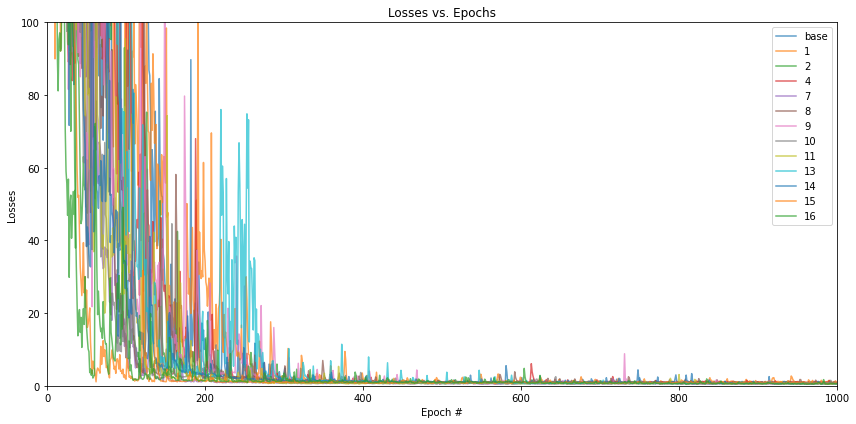

In [34]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
plt.plot(np.arange(len(losses_base)), losses_base, label='base', alpha=0.7)
plt.plot(np.arange(len(losses_1)), losses_1, label='1', alpha=0.7)
plt.plot(np.arange(len(losses_2)), losses_2, label='2', alpha=0.7) 
#plt.plot(np.arange(len(losses_3)), losses_3, label='3', alpha=0.7) # fc1 = 200 and fc2 = 150
plt.plot(np.arange(len(losses_4)), losses_4, label='4', alpha=0.7)
#plt.plot(np.arange(len(losses_5)), losses_5, label='5', alpha=0.7)
#plt.plot(np.arange(len(losses_6)), losses_6, label='6', alpha=0.7) # lr = 1e-4
plt.plot(np.arange(len(losses_7)), losses_7, label='7', alpha=0.7)
plt.plot(np.arange(len(losses_8)), losses_8, label='8', alpha=0.7)
plt.plot(np.arange(len(losses_9)), losses_9, label='9', alpha=0.7)
plt.plot(np.arange(len(losses_10)), losses_10, label='10', alpha=0.7)
plt.plot(np.arange(len(losses_11)), losses_11, label='11', alpha=0.7)
#plt.plot(np.arange(len(losses_12)), losses_12, label='12', alpha=0.7) # qtarget_update = 800
plt.plot(np.arange(len(losses_13)), losses_13, label='13', alpha=0.7) # mem_size = 2000
plt.plot(np.arange(len(losses_14)), losses_14, label='14', alpha=0.7) # mem_size = 3000
plt.plot(np.arange(len(losses_15)), losses_15, label='15', alpha=0.7) # epsdecay
plt.plot(np.arange(len(losses_16)), losses_16, label='16', alpha=0.7)  
plt.legend()
plt.xlim([0,1000])
plt.ylim([0,100])
plt.title('Losses vs. Epochs')
plt.ylabel('Losses')
plt.xlabel('Epoch #')
plt.show()

Rewards vs Epochs

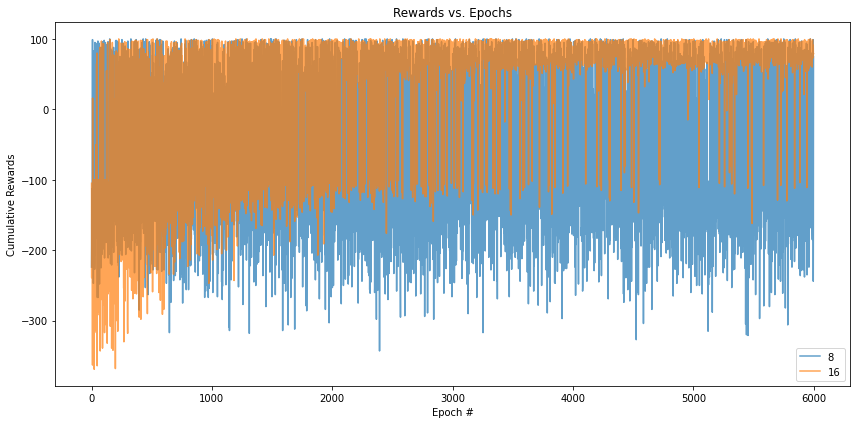

In [49]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
#plt.plot(np.arange(len(cum_reward_base)), cum_reward_base, label='base', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_1)), cum_reward_1, label='1', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_2)), cum_reward_2, label='2', alpha=0.7) 
#plt.plot(np.arange(len(cum_reward_4)), cum_reward_4, label='4', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_7)), cum_reward_7, label='7', alpha=0.7)
plt.plot(np.arange(len(cum_reward_8)), cum_reward_8, label='8', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_9)), cum_reward_9, label='9', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_10)), cum_reward_10, label='10', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_11)), cum_reward_11, label='11', alpha=0.7)
#plt.plot(np.arange(len(cum_reward_13)), cum_reward_13, label='13', alpha=0.7) # mem_size = 2000
#plt.plot(np.arange(len(cum_reward_14)), cum_reward_14, label='14', alpha=0.7) # mem_size = 3000
#plt.plot(np.arange(len(cum_reward_15)), cum_reward_15, label='15', alpha=0.7) 
plt.plot(np.arange(len(cum_reward_16)), cum_reward_16, label='16', alpha=0.7) # Less negative rewards over time
plt.legend()
#plt.xlim([5900,6000])
#plt.ylim([0,150])
plt.title('Rewards vs. Epochs')
plt.ylabel('Cumulative Rewards')
plt.xlabel('Epoch #')
plt.show()

Further experiments with cumulative windowed reward

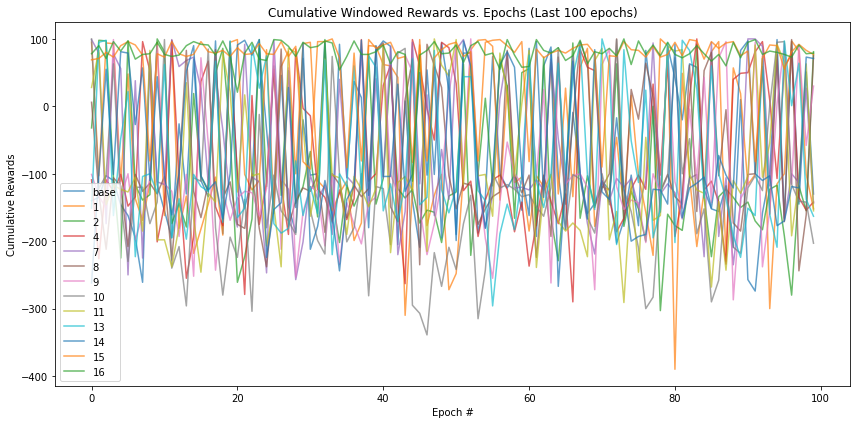

In [35]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
plt.plot(np.arange(len(rewards_window_base)), rewards_window_base, label='base', alpha=0.7)
plt.plot(np.arange(len(rewards_window_1)), rewards_window_1, label='1', alpha=0.7)
plt.plot(np.arange(len(rewards_window_2)), rewards_window_2, label='2', alpha=0.7) 
plt.plot(np.arange(len(rewards_window_4)), rewards_window_4, label='4', alpha=0.7)
plt.plot(np.arange(len(rewards_window_7)), rewards_window_7, label='7', alpha=0.7)
plt.plot(np.arange(len(rewards_window_8)), rewards_window_8, label='8', alpha=0.7)
plt.plot(np.arange(len(rewards_window_9)), rewards_window_9, label='9', alpha=0.7)
plt.plot(np.arange(len(rewards_window_10)), rewards_window_10, label='10', alpha=0.7)
plt.plot(np.arange(len(rewards_window_11)), rewards_window_11, label='11', alpha=0.7)
plt.plot(np.arange(len(rewards_window_13)), rewards_window_13, label='13', alpha=0.7) # mem_size = 2000
plt.plot(np.arange(len(rewards_window_14)), rewards_window_14, label='14', alpha=0.7) # mem_size = 3000
plt.plot(np.arange(len(rewards_window_15)), rewards_window_15, label='15', alpha=0.7) 
plt.plot(np.arange(len(rewards_window_16)), rewards_window_16, label='16', alpha=0.7) 
plt.legend()
#plt.xlim([0,1000])
#plt.ylim([0,100])
plt.title('Cumulative Windowed Rewards vs. Epochs (Last 100 epochs)')
plt.ylabel('Cumulative Rewards')
plt.xlabel('Epoch #')
plt.show()

Avg Reward

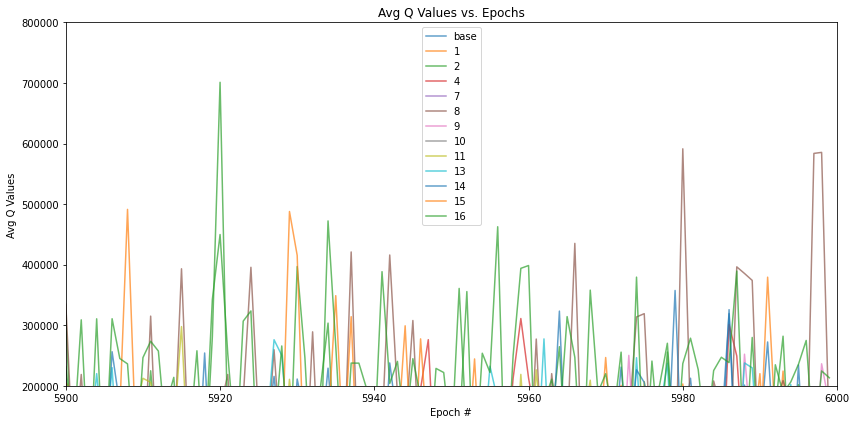

In [44]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
plt.plot(np.arange(len(avg_qvalues_ep_base)), avg_qvalues_ep_base, label='base', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_1)), avg_qvalues_ep_1, label='1', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_2)), avg_qvalues_ep_2, label='2', alpha=0.7) 
plt.plot(np.arange(len(avg_qvalues_ep_4)), avg_qvalues_ep_4, label='4', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_7)), avg_qvalues_ep_7, label='7', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_8)), avg_qvalues_ep_8, label='8', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_9)), avg_qvalues_ep_9, label='9', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_10)), avg_qvalues_ep_10, label='10', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_11)), avg_qvalues_ep_11, label='11', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_13)), avg_qvalues_ep_13, label='13', alpha=0.7) # mem_size = 2000
plt.plot(np.arange(len(avg_qvalues_ep_14)), avg_qvalues_ep_14, label='14', alpha=0.7) # mem_size = 3000
plt.plot(np.arange(len(avg_qvalues_ep_15)), avg_qvalues_ep_15, label='15', alpha=0.7) # eps decay
plt.plot(np.arange(len(avg_qvalues_ep_16)), avg_qvalues_ep_16, label='16', alpha=0.7) # gamma and eps decay
plt.legend()
plt.xlim([5900,6000]) # Last 100 epochs
plt.ylim([200000,800000])
plt.title('Avg Q Values vs. Epochs')
plt.ylabel('Avg Q Values')
plt.xlabel('Epoch #')
plt.show()

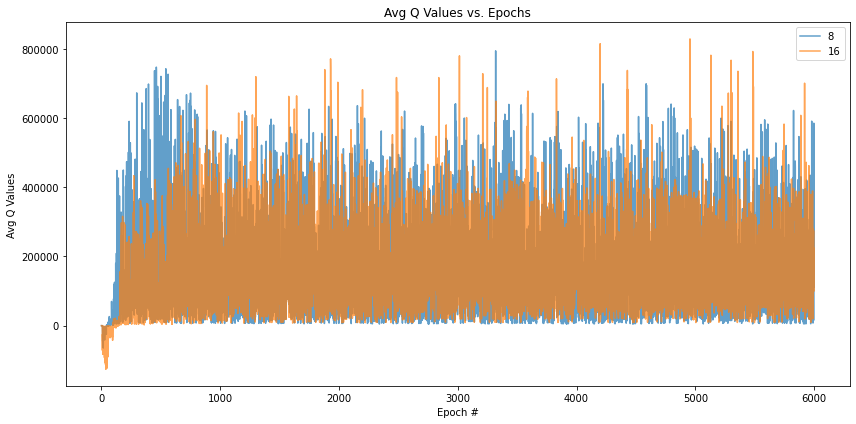

In [47]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
#plt.plot(np.arange(len(avg_qvalues_ep_base)), avg_qvalues_ep_base, label='base', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_1)), avg_qvalues_ep_1, label='1', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_2)), avg_qvalues_ep_2, label='2', alpha=0.7) 
#plt.plot(np.arange(len(avg_qvalues_ep_4)), avg_qvalues_ep_4, label='4', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_7)), avg_qvalues_ep_7, label='7', alpha=0.7)
plt.plot(np.arange(len(avg_qvalues_ep_8)), avg_qvalues_ep_8, label='8', alpha=0.7) #  
#plt.plot(np.arange(len(avg_qvalues_ep_9)), avg_qvalues_ep_9, label='9', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_10)), avg_qvalues_ep_10, label='10', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_11)), avg_qvalues_ep_11, label='11', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_13)), avg_qvalues_ep_13, label='13', alpha=0.7) # mem_size = 2000
#plt.plot(np.arange(len(avg_qvalues_ep_14)), avg_qvalues_ep_14, label='14', alpha=0.7) # mem_size = 3000
#plt.plot(np.arange(len(avg_qvalues_ep_15)), avg_qvalues_ep_15, label='15', alpha=0.7) # epsdecay
plt.plot(np.arange(len(avg_qvalues_ep_16)), avg_qvalues_ep_16, label='16', alpha=0.7) # gamma and eps decay (Clearly the best choice)
plt.legend()
#plt.xlim([5900,6000]) # Last 100 epochs
#plt.ylim([200000,800000])
plt.title('Avg Q Values vs. Epochs')
plt.ylabel('Avg Q Values')
plt.xlabel('Epoch #')
plt.show()

### Max Q-Values

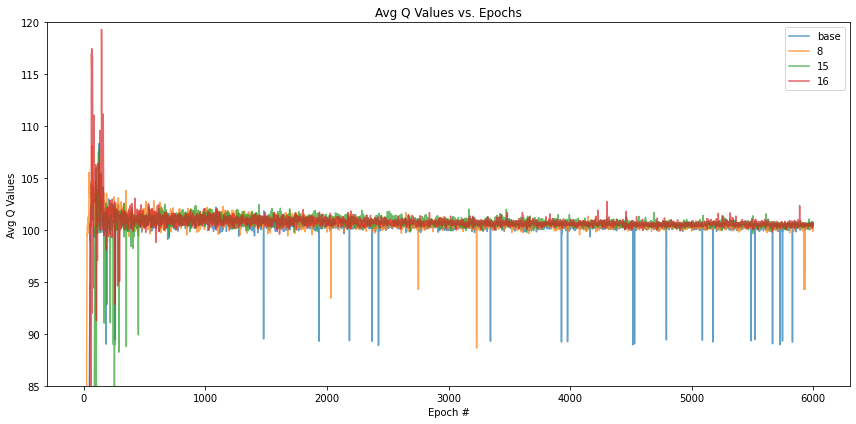

In [51]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
#ax = fig.add_subplot(111)
plt.plot(np.arange(len(max_qvalues_ep_base)), max_qvalues_ep_base, label='base', alpha=0.7)
plt.plot(np.arange(len(max_qvalues_ep_8)), max_qvalues_ep_8, label='8', alpha=0.7) # Clearly the best choice 
plt.plot(np.arange(len(max_qvalues_ep_15)), max_qvalues_ep_15, label='15', alpha=0.7)
plt.plot(np.arange(len(max_qvalues_ep_16)), max_qvalues_ep_16, label='16', alpha=0.7)
#plt.plot(np.arange(len(avg_qvalues_ep_13)), avg_qvalues_ep_13, label='13', alpha=0.7) # mem_size = 2000
#plt.plot(np.arange(len(avg_qvalues_ep_14)), avg_qvalues_ep_14, label='14', alpha=0.7) # mem_size = 3000
plt.legend()
#plt.xlim([5900,6000]) # Last 100 epochs
plt.ylim([85,120])
plt.title('Max Q Values vs. Epochs')
plt.ylabel('Max Q Values')
plt.xlabel('Epoch #')
plt.show()

In [ ]:
# import random

# def hyper_param_ch_game():
#     lrs = [uniform(3e-4,1e-2) for p in range(0, 10)]
#     discount_factors = [uniform(.99,.7) for p in range(0, 10)]
#     epsilon_decay
#     #nbatch_sizes = [randrange(64,512) for p in range(0, 10)]
#     #optimizers = ['adam', 'adagrad', 'adadelta', 'sgd', 'rmsprop']
#     loss_fun = 'mse'
#     dueling = [False]
#     ddqn = [False]
#     per = [False]
    
#     num_epochs=100, max_timesteps=128, epsilon_start=1, 
#                                              epsilon_end=0.1, epsilon_decay=0.9994, qtarget_update=1000,
#                                              fc1_dim=75, fc2_dim=50,learning_rate=0.001, gamma=0.9,
#                                              loss_fun='mse',conv=False,dueling=False,ddqn=True,per=True
    
#     for lr, nbatch_size, discount_factor in zip(lrs, nbatch_sizes, discount_factors):
#     optimizer = random.choice(optimizers)
#     args = hyper_param(lr, discount_factor, 
#                        loss_fun, dueling, ddqn, per)
#     # pass args into the main function 
#     rewards_total2, rewards_window2, rewards2, losses2 = DQN(num_epochs=100, max_timesteps=128, epsilon_start=1, 
#                                              epsilon_end=0.1, epsilon_decay=0.9994, qtarget_update=1000,
#                                              fc1_dim=75, fc2_dim=50,learning_rate=0.001, gamma=0.9,
#                                              loss_fun='mse',conv=False,dueling=False,ddqn=True,per=True)
#     agent = main(args)
#     plt.figure()
#     plt.plot(iters, ep_loss)
#     plt.title("Training Curve (batch_size={}, lr={:.4f},discount_factor={:.4f}, optimizer = {})".format(nbatch_size, lr, discount_factor, optimizer))
#     plt.xlabel("episodes")
#     plt.ylabel("Loss")
#     plt.grid()
# game_type = 'MountainCar-v0'
# hyper_param_ch_game(game_type)

# 4 Last experiment (Dueling Double Deep Q Network With Prioritized Replay)

In [ ]:
# Plot the Losses

fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(np.arange(len(losses1)), losses1)
plt.ylabel('Losses')
plt.xlabel('Episode #')
plt.show()

NameError: name 'plt' is not defined

In [ ]:
#np.where(rewards[11]>100)
#sum(rewards[90:100])
#np.unique(rewards[90])
for i in range(len(rewards1)):
    a, _ = np.unique(rewards1[i], return_counts=True)
    b_sum = np.sum(a[a == 50])
    print(b_sum)

NameError: name 'rewards1' is not defined

## Ablation Study

In [ ]:
# We shall test the following hypothesis for the Ablation study (Double DDQN / Dueling and Prioritised Experienced Replay) using the best hyperparameter choice for the Vanilla DQN

# Hyperparameters choice

state_size=400 
fc1=150 
fc2=100 
action_size=4
epochs=6000
lr=1e-3 
gamma=0.95 
eps=1
eps_decay=0.999
batch_size=200
mem_size=1000
qtarget_update=500




In [ ]:
torch.cuda.is_available()

False

In [8]:

print("hello")
end = time.time()
print(end - start)

hello
0.00012493133544921875


In [52]:
import copy

def isEmpty(a):
    return all(map(isEmpty,a)) if isinstance(a, list) else False


def Ablation_DQN(num_epochs, max_timesteps, qtarget_update, fc1_dim, fc2_dim, learning_rate, gamma, eps, eps_decay,
                 dueling, ddqn, per, loss_fun='mse', conv=False, epsilon_end=0):
    """Deep Q-Learning.
    
    Params
    ======
        n_episodes (int): maximum number of training episodes
        max_timesteps (int): maximum number of timesteps per episode
        epsilon_start (float): starting value of epsilon, for epsilon-greedy action selection
        epsilon_end (float): minimum value of epsilon
        epsilon_decay (float): multiplicative factor (per episode) for decreasing epsilon
    """
    
    # Start wall-clock time count
    start = time.time()

    # Set torch device to cuda if available else set to cpu
    device = torch.device('cpu')
    if torch.cuda.is_available():
        device = torch.device('cuda')

    max_steps = max_timesteps
    i_steps = 0
    
    rewards_total = []                                      # List containing rewards from each episode
    rewards_window = deque(maxlen=100)                       # Last 100 rewards

    rewards = np.zeros([num_epochs,max_steps])              # Rewards for each timestep and episode
    #losses = np.zeros([num_epochs,max_steps])               # Losses for each timestep and episode
    #qvalues = np.zeros([num_epochs,max_steps])              # QValues for each timestep and episode
    
    epsilon_list = []                                       # Keep track of epsilon values
    episode_durations_total = []                            # Keep track of episode durations
    qvalues_estimates = []
    qvalues_estimates_avg = []
    qvalues_estimates_max = []
    losses = []
    losses_total = []
    
    
    epsilon = eps                                           # Initialize epsilon
    epsilon_decay = eps_decay                               # Initialize epsilon decay
#     if isinstance(env.observation_space, gym.spaces.Discrete):
#         state_dim=env.observation_space.n
#     elif isinstance(env.observation_space, gym.spaces.Box):
#         state_shape = env.observation_space.shape
#         state_dim = state_shape[0] if len(state_shape) == 1 else state_shape 
    
#     action_dim=env.action_space.n
    
#     agent = DQNAgent(state_size=state_dim, fc1_dim=64, fc2_dim=64, 
#                      action_size=action_dim, seed=0, lr=5e-4, gamma=0.99)
    
    
    
    state_size_decoded = 400 #env.observation_space_decoded
    action_size = 4 #env.action_space

    # Initialise DQN agent based on hyperparameters
    agent = DQNAgent(state_size=state_size_decoded, fc1_dim=fc1_dim, fc2_dim=fc2_dim, fc3_dim=64, 
                action_size=action_size, seed=0, learning_rate=learning_rate, gamma=gamma, loss_fun=loss_fun,
                conv=conv,ddqn=ddqn,dueling=dueling,per=per)
    

    # Initialise the environment (Easy)
    # env = MapWalkingEnv(6,6)
    
    # Initialise the environment (Complex)
    env = MapWalkingEnv(10,10)

    for i_epoch in range(1, num_epochs+1):
        
        # Each epoch
        state = env.reset()
        #state_decoded = np.array([v for _,v in enumerate(env.decode(state))])
        state_ = env.decode_grid(state) + np.random.rand(1,400)/100.0
        state = torch.from_numpy(state_).float().to(device)
        #states_total = 16
        #data = [[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]]
        #def encode(data, states_total):
        #    targets = np.array(data).reshape(-1)
        #    return np.eye(states_total)[targets]
        
        #m = encode(data,states_total)
        #state = m[state]
        #print(state)
        
        losses_epoch = []
 
        score = 0
        moves = 0
        status = 1
        cum_reward = 0
        
        qvalue_estimates_epoch = []
        max_qvalue = 0

        # Each training step in the environment
        while (status == 1):
            moves+=1
            i_steps+=1
            
            valid_actions = [0,1,2,3] #env.valid_actions()
 
            action = agent.select_action(state, valid_actions, epsilon)              

            next_state, reward, terminal, _ = env.step(action)
            
            next_state_ = env.decode_grid(next_state) + np.random.rand(1,400)/100.0
            next_state = torch.from_numpy(next_state_).float().to(device)

            agent.step(state, action, reward, next_state, terminal)

            rewards[i_epoch-1][moves-1] = reward
            state = next_state
            
            # Save Cumulative Reward
            cum_reward += reward
            
            qvalue_estimates_epoch.append(agent.qvalues_estimates)
            qvalues_estimates.append(agent.qvalues_estimates)
            
            #print(agent.qvalues_estimates)
            if not isEmpty(qvalues_estimates):
                max_qvalue = max(max_qvalue,qvalues_estimates[-1][0])
            else:
                max_qvalue = max(max_qvalue,0)

            if len(agent.losses) > 0:
                losses_epoch.append(agent.losses[-1])

            # Update the target network, copying all weights and biases in DQN 
            # (2000 timesteps or 10 episodes if each episode has reached a maximum timesteps of 200)
            if i_steps % qtarget_update == 0:
                agent.update_target_network()
            
            #if reward > 0:
            #    print('Found',reward)

            if terminal or (moves >= max_steps):
                status = 0         
            
        epsilon = max(epsilon_end, epsilon_decay*epsilon) # Decrease epsilon with epsilon_decay rate
        
        if not isEmpty(qvalue_estimates_epoch):
            qvalues_estimates_avg.append(np.mean(qvalue_estimates_epoch))
        else:
            qvalues_estimates_avg.append(0)

        if not isEmpty(losses_epoch):
            losses_total.append(np.mean(losses_epoch))  # Save losses between the networks q-values (for each epoch)    
        else:
            losses_total.append(0)
        
        rewards_window.append(cum_reward)       # save most recent reward

        rewards_total.append(cum_reward)        # save cumulative reward
        episode_durations_total.append(moves)   
        qvalues_estimates.append(agent.qvalues_estimates)
        qvalues_estimates_max.append(max_qvalue)
        epsilon_list.append(epsilon)
        
        if i_epoch % 100 == 0:
            print('\rEpisode {}\tAvgRds: {:.2f}'.format(i_epoch, np.mean(rewards_window)/i_epoch), end="")
            print('\tMaxRds: {0:.2f}'.format(np.max(rewards_window)), end="")
            print('\tEps: {0:.2f}'.format(epsilon))

#         if i_epoch % 100 == 0:
#             rewards_averaged.append(np.mean(rewards_window))
#             print('\n\rEpisode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(rewards_window)))
#         if np.mean(rewards_window)>=100.0:
#             print('\nEnvironment solved in {:d} episodes!\tAverage Score: {:.2f}'.format(i_episode-100, np.mean(rewards_window)))
#             torch.save(agent.qnetwork_local.state_dict(), 'checkpoint.pth')
#             break
    losses = np.array(agent.losses)
    end = time.time()
    walltime = (end - start)
    return rewards_total, rewards_window, rewards, losses, losses_total, \
           qvalues_estimates, qvalues_estimates_avg, qvalues_estimates_max, episode_durations_total, epsilon_list, walltime, agent.q_network



def eval_policy_net(env, agent, verbose = False):
        scores = []
        for i_episode in range(10):
            # initialize initial state
            state = env.reset()
            state = torch.from_numpy(state)

            for t in range(100):
                # get the action based on state by greedy policy
                action = agent.greedy_policy(state)

                # execute action in environment
                obs, _, done, _ = env.step(action.item())
                state = torch.from_numpy(obs)

                if done: 
                    scores.append(t + 1)
                    if verbose:
                        print("Episode {} finished after {} timesteps" \
                                        .format(i_episode, t+1))
                    break
        net_score = np.array(scores, dtype = float)
        
        if verbose:
            print("policy net scores -- mean: {}, var: {}, max: {}, min: {}".format(
                            net_score.mean(), net_score.var(), net_score.max(), net_score.min()
                            ))
        else:
            print("policy net scores -- mean:", net_score.mean())
            # print(net_score)
        return net_score.mean()

In [20]:
 a=[0]
 a[0]

0

In [ ]:
reward = cum_rewards #reward['reward']

avg = 10
window = int(len(reward)/avg)
fig, ((ax1), (ax2)) = plt.subplots(2, 1, figsize=[9,9]);
rolling_mean = pd.Series(reward).rolling(window).mean()
std = pd.Series(reward).rolling(window).std()
ax1.plot(rolling_mean)
ax1.fill_between(range(len(reward)),rolling_mean-std, rolling_mean+std, color='orange', alpha=0.2)
ax1.set_title('Average Reward 12 x 12 grid (last {}-episode window)'.format(avg))
ax1.set_xlabel('Episode'); 
ax1.set_ylabel('Average Reward')

In [ ]:
# #state_size=400 
# #fc1=150 
# #fc2=100 
# #action_size=4
# #epochs=6000
# #lr=1e-3 
# #gamma=0.95 
# #eps=0.6 
# #batch_size=200
# #mem_size=1000
# #qtarget_update=500


# # num_epochs, max_timesteps, qtarget_update, fc1_dim, fc2_dim, learning_rate, gamma, epsilon, 
# #  dueling, ddqn, per, loss_fun='mse', conv=False, 
# rewards_total, rewards_window, rewards, losses, qvalues_estimates, episode_durations, epsilon_list, model = \
# Ablation_DQN(num_epochs=6000, max_timesteps=80, qtarget_update=500, 
# fc1_dim=150, fc2_dim=100, learning_rate=1e-3, gamma=0.9, eps=1.0, eps_decay=0.999,
# dueling=False,ddqn=False,per=False,loss_fun='mse',conv=False,epsilon_end=0)

In [24]:
a=[1,2]
a[-1]

2

In [ ]:

# num_epochs, max_timesteps, qtarget_update, fc1_dim, fc2_dim, learning_rate, gamma, epsilon, 
#  dueling, ddqn, per, loss_fun='mse', conv=False, 
rewards_total_0, rewards_window_0, rewards_0, losses_0, losses_total_0, qvalues_estimates_0, \
qvalues_estimates_avg_0, episode_durations_total_0, epsilon_list_0, model_0 = \
Ablation_DQN(num_epochs=200, max_timesteps=80, qtarget_update=1, 
fc1_dim=150, fc2_dim=100, learning_rate=1e-3, gamma=0.9, eps=1.0, eps_decay=0.999,
dueling=False,ddqn=False,per=False,loss_fun='mse',conv=False,epsilon_end=0)

Episode 100	AvgRds: -1.68	MaxRds: 100.00	Eps: 0.90
Episode 200	AvgRds: -0.74	MaxRds: 100.00	Eps: 0.82


In [ ]:
n = 4
one_hot = torch.nn.functional.one_hot(b.to(torch.int64), n)

In [45]:
np.array(-10.781319, dtype=np.float32).item()

-10.781318664550781

In [44]:
max(0,[np.array(-10.781319, dtype=np.float32).item()])

TypeError: ignored

In [133]:
labeldqn = []
labeldqn.append("DQN")
labeldqn.append("Double-DQN")
labeldqn.append("Dueling-DQN")
labeldqn.append("PER-DQN")
labeldqn.append("Dueling-PER-DQN")
labeldqn.append("Double-PER-DQN")
labeldqn.append("Dueling-Double DQN")
labeldqn.append("Dueling-Double-PER-DQN")

In [57]:
# Improvements
# 8 experiments using the exactly same static parameters over all combinations of Double DQN (DDQN), Dueling Network (Dueling) and Prioritized Experience Replay (PER) options respectively
abl = []
# # Double DQN / Dueling / PER
abl.append([False, False, False])  "DQN"
abl.append([True, False, False])  "Double-DQN"
abl.append([False, True, False]) "Dueling-DQN"
abl.append([False, False, True]) "PER-DQN"
abl.append([False, True, True]) "Dueling-PER-DQN"
abl.append([True, False, True]) "Double-PER-DQN"
abl.append([True, True, False]) "Dueling-Double DQN"
abl.append([True, True, True]) "Dueling-Double-PER-DQN"

epochs = 2500
state_size = 400 
fc1 = 150 
fc2 = 100 
action_size = 4
lr=1e-3 
gamma = 0.95 
eps = 1.0
eps_decay=0.999
batch_size = 200
mem_size = 1000
qtarget_update = 500
timesteps = 80 #timesteps = 100


# for i_abl in abl:
#     print(i_abl)
rewards_total_0, rewards_window_0, rewards_0, losses_0, losses_total_0, qvalues_estimates_0, qvalues_estimates_avg_0, qvalues_estimates_max_0, \
episode_durations_total_0, epsilon_list_0, walltime_0, model_0 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[0][1], dueling=abl[0][1], per=abl[0][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_1, rewards_window_1, rewards_1, losses_1, losses_total_1, qvalues_estimates_1, qvalues_estimates_avg_1, qvalues_estimates_max_1,\
episode_durations_total_1, epsilon_list_1, walltime_1, model_1 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[1][1], dueling=abl[1][1], per=abl[1][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_2, rewards_window_2, rewards_2, losses_2, losses_total_2, qvalues_estimates_2, qvalues_estimates_avg_2, qvalues_estimates_max_2,\
episode_durations_total_2, epsilon_list_2, walltime_2, model_2 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[2][1], dueling=abl[2][1], per=abl[2][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_3, rewards_window_3, rewards_3, losses_3, losses_total_3, qvalues_estimates_3, qvalues_estimates_avg_3, qvalues_estimates_max_3,\
episode_durations_total_3, epsilon_list_3, walltime_3, model_3 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[3][1], dueling=abl[3][1], per=abl[3][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_4, rewards_window_4, rewards_4, losses_4, losses_total_4, qvalues_estimates_4, qvalues_estimates_avg_4, qvalues_estimates_max_4,\
episode_durations_total_4, epsilon_list_4, walltime_4, model_4 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[4][1], dueling=abl[4][1], per=abl[4][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_5, rewards_window_5, rewards_5, losses_5, losses_total_5, qvalues_estimates_5, qvalues_estimates_avg_5, qvalues_estimates_max_5,\
episode_durations_total_5, epsilon_list_5, walltime_5, model_5 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[5][1], dueling=abl[5][1], per=abl[5][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_6, rewards_window_6, rewards_6, losses_6, losses_total_6, qvalues_estimates_6, qvalues_estimates_avg_6, qvalues_estimates_max_6,\
episode_durations_total_6, epsilon_list_6, walltime_6, model_6 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[6][1], dueling=abl[6][1], per=abl[6][2],loss_fun='mse',conv=False,epsilon_end=0)



rewards_total_7, rewards_window_7, rewards_7, losses_7, losses_total_7, qvalues_estimates_7, qvalues_estimates_avg_7, qvalues_estimates_max_7,\
episode_durations_total_7, epsilon_list_7, walltime_7, model_7 = \
Ablation_DQN(num_epochs=epochs, max_timesteps=timesteps, qtarget_update=qtarget_update, 
fc1_dim=fc1, fc2_dim=fc2, learning_rate=lr, gamma=gamma, eps=eps, eps_decay=eps_decay,
ddqn=abl[7][1], dueling=abl[7][1], per=abl[7][2],loss_fun='mse',conv=False,epsilon_end=0)

#filename = 'checkpoint_'+i_abl+'.pth'
#torch.save(model.state_dict(), 'checkpoint.pth')

# rewards_total_0, rewards_window_0, rewards_0, losses_0, qvalues_estimates_0, qvalues_estimates_total_0, \
# episode_durations_total_0, epsilon_list_0, model_0 = \
# Ablation_DQN(num_epochs=1000, max_timesteps=80, qtarget_update=500, 
# fc1_dim=150, fc2_dim=100, learning_rate=1e-3, gamma=0.9, eps=1.0, eps_decay=0.999,
# ddqn=abl[0][1], dueling=abl[0][1], per=abl[0][2],loss_fun='mse',conv=False,epsilon_end=0)
# filename = 'checkpoint_'+i_abl+'.pth'
# torch.save(model.state_dict(), 'checkpoint.pth')
# end = time.time()
# #print(end - start)
# # Plot the Rewards
# fig = plt.figure()
# ax = fig.add_subplot(111)
# plt.plot(np.arange(len(rewards_total3)), rewards_total3)
# plt.ylabel('Rewards')
# plt.xlabel('Epoch #')
# plt.show()

Episode 100	AvgRds: -1.91	MaxRds: 99.00	Eps: 0.90
Episode 200	AvgRds: -0.89	MaxRds: 99.00	Eps: 0.82
Episode 300	AvgRds: -0.61	MaxRds: 98.00	Eps: 0.74
Episode 400	AvgRds: -0.48	MaxRds: 88.00	Eps: 0.67
Episode 500	AvgRds: -0.38	MaxRds: 100.00	Eps: 0.61
Episode 600	AvgRds: -0.33	MaxRds: 92.00	Eps: 0.55
Episode 700	AvgRds: -0.29	MaxRds: 97.00	Eps: 0.50
Episode 800	AvgRds: -0.22	MaxRds: 96.00	Eps: 0.45
Episode 900	AvgRds: -0.25	MaxRds: 96.00	Eps: 0.41
Episode 1000	AvgRds: -0.22	MaxRds: 94.00	Eps: 0.37
Episode 1100	AvgRds: -0.19	MaxRds: 97.00	Eps: 0.33
Episode 1200	AvgRds: -0.18	MaxRds: 100.00	Eps: 0.30
Episode 1300	AvgRds: -0.19	MaxRds: 98.00	Eps: 0.27
Episode 1400	AvgRds: -0.15	MaxRds: 99.00	Eps: 0.25
Episode 1500	AvgRds: -0.16	MaxRds: 100.00	Eps: 0.22
Episode 1600	AvgRds: -0.14	MaxRds: 95.00	Eps: 0.20
Episode 1700	AvgRds: -0.13	MaxRds: 99.00	Eps: 0.18
Episode 1800	AvgRds: -0.12	MaxRds: 100.00	Eps: 0.17
Episode 1900	AvgRds: -0.13	MaxRds: 100.00	Eps: 0.15
Episode 2000	AvgRds: -0.12	MaxRds: 

In [9]:
import pickle

# with open('advtask_ablation.pickle', 'wb') as f:
#     pickle.dump([rewards_total_0, rewards_window_0, rewards_0, losses_0, losses_total_0, qvalues_estimates_0, qvalues_estimates_avg_0, qvalues_estimates_max_0, \
#     episode_durations_total_0, epsilon_list_0, walltime_0, model_0,\
#     rewards_total_1, rewards_window_1, rewards_1, losses_1, losses_total_1, qvalues_estimates_1, qvalues_estimates_avg_1, qvalues_estimates_max_1,\
#     episode_durations_total_1, epsilon_list_1, walltime_1, model_1, \
#     rewards_total_2, rewards_window_2, rewards_2, losses_2, losses_total_2, qvalues_estimates_2, qvalues_estimates_avg_2, qvalues_estimates_max_2,\
#     episode_durations_total_2, epsilon_list_2, walltime_2, model_2, \
#     rewards_total_3, rewards_window_3, rewards_3, losses_3, losses_total_3, qvalues_estimates_3, qvalues_estimates_avg_3, qvalues_estimates_max_3,\
#     episode_durations_total_3, epsilon_list_3, walltime_3, model_3, \
#     rewards_total_4, rewards_window_4, rewards_4, losses_4, losses_total_4, qvalues_estimates_4, qvalues_estimates_avg_4, qvalues_estimates_max_4,\
#     episode_durations_total_4, epsilon_list_4, walltime_4, model_4, \
#     rewards_total_5, rewards_window_5, rewards_5, losses_5, losses_total_5, qvalues_estimates_5, qvalues_estimates_avg_5, qvalues_estimates_max_5,\
#     episode_durations_total_5, epsilon_list_5, walltime_5, model_5, \
#     rewards_total_6, rewards_window_6, rewards_6, losses_6, losses_total_6, qvalues_estimates_6, qvalues_estimates_avg_6, qvalues_estimates_max_6,\
#     episode_durations_total_6, epsilon_list_6, walltime_6, model_6, \
#     rewards_total_7, rewards_window_7, rewards_7, losses_7, losses_total_7, qvalues_estimates_7, qvalues_estimates_avg_7, qvalues_estimates_max_7, \
#     episode_durations_total_7, epsilon_list_7, walltime_7, model_7], f)

# !cp advtask_ablation.pickle 'drive/My Drive/City_University/Deep_Reinforcement_Learning/advtask_ablation.pickle'

# Load pickle files to repeat the experiments for Environments 1 and 2  
import pickle
with open('drive/My Drive/City_University/Deep_Reinforcement_Learning/advtask_ablation.pickle','rb') as f:   
    rewards_total_0, rewards_window_0, rewards_0, losses_0, losses_total_0, qvalues_estimates_0, qvalues_estimates_avg_0, qvalues_estimates_max_0, \
    episode_durations_total_0, epsilon_list_0, walltime_0, model_0,\
    rewards_total_1, rewards_window_1, rewards_1, losses_1, losses_total_1, qvalues_estimates_1, qvalues_estimates_avg_1, qvalues_estimates_max_1,\
    episode_durations_total_1, epsilon_list_1, walltime_1, model_1, \
    rewards_total_2, rewards_window_2, rewards_2, losses_2, losses_total_2, qvalues_estimates_2, qvalues_estimates_avg_2, qvalues_estimates_max_2,\
    episode_durations_total_2, epsilon_list_2, walltime_2, model_2, \
    rewards_total_3, rewards_window_3, rewards_3, losses_3, losses_total_3, qvalues_estimates_3, qvalues_estimates_avg_3, qvalues_estimates_max_3,\
    episode_durations_total_3, epsilon_list_3, walltime_3, model_3, \
    rewards_total_4, rewards_window_4, rewards_4, losses_4, losses_total_4, qvalues_estimates_4, qvalues_estimates_avg_4, qvalues_estimates_max_4,\
    episode_durations_total_4, epsilon_list_4, walltime_4, model_4, \
    rewards_total_5, rewards_window_5, rewards_5, losses_5, losses_total_5, qvalues_estimates_5, qvalues_estimates_avg_5, qvalues_estimates_max_5,\
    episode_durations_total_5, epsilon_list_5, walltime_5, model_5, \
    rewards_total_6, rewards_window_6, rewards_6, losses_6, losses_total_6, qvalues_estimates_6, qvalues_estimates_avg_6, qvalues_estimates_max_6,\
    episode_durations_total_6, epsilon_list_6, walltime_6, model_6, \
    rewards_total_7, rewards_window_7, rewards_7, losses_7, losses_total_7, qvalues_estimates_7, qvalues_estimates_avg_7, qvalues_estimates_max_7, \
    episode_durations_total_7, epsilon_list_7, walltime_7, model_7 = pickle.load(f)


Analysis of Results (Quantitatively and Qualitatively)

In [165]:
def calculate_return(reward_list):
    return_j = []
    for i in range(len(reward_list)):
        return_i = []
        for j,val in enumerate(reward_list[i]):
            return_i.append(val*pow(0.95,j))
        return_j.append(return_i) 
    return np.array(return_j)

returns_0 = calculate_return(rewards_0)
returns_1 = calculate_return(rewards_1)
returns_2 = calculate_return(rewards_2)
returns_3 = calculate_return(rewards_3)
returns_4 = calculate_return(rewards_4)
returns_5 = calculate_return(rewards_5)
returns_6 = calculate_return(rewards_6)
returns_7 = calculate_return(rewards_7)



In [161]:
# def plot_returns(returns, steps_each=100, label_plot=''):
#     plt.figure(figsize=(8, 4))
    
#     means = returns.mean(axis=1)
#     y_std = np.std(returns, axis=1)
#     x_values = np.arange(len(means))* steps_each
    
#     plt.plot(x_values, means, label=label_plot, c="b")
#     plt.fill_between(x_values, y2=means + y_std, y1=means - y_std, color="b", alpha=0.2)
    

#     plt.xlabel("Steps", fontsize=14)
#     plt.ylabel("Discounted Return", fontsize=14)
#     plt.title("Discounted Return vs Environment Steps", fontsize=14)
#     plt.legend(fontsize=14)
#     plt.tight_layout()

Discounted Return vs Environment Steps

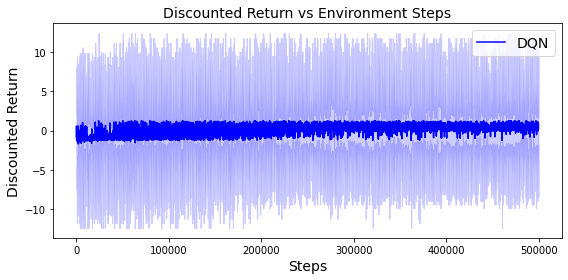

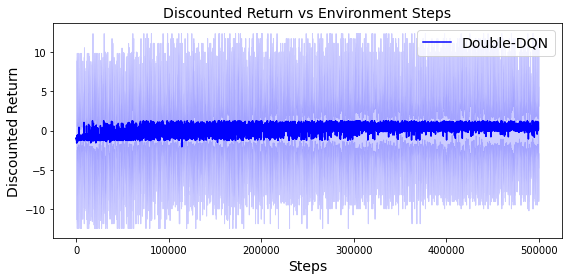

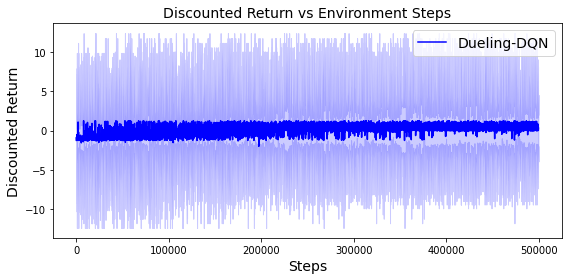

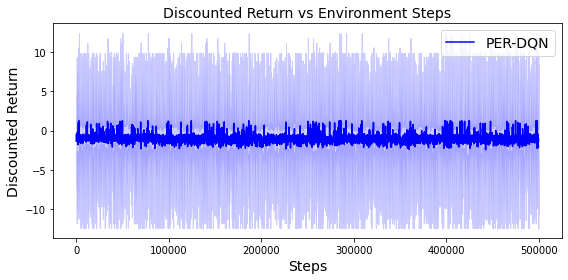

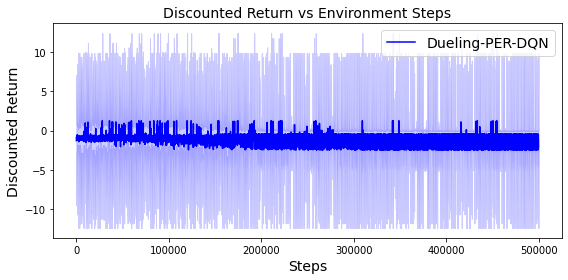

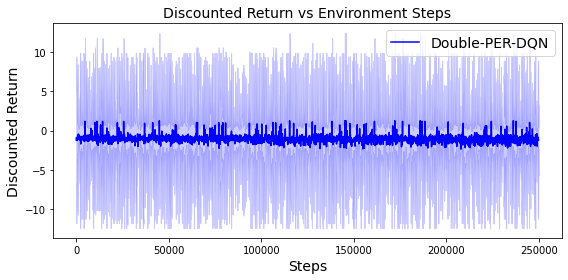

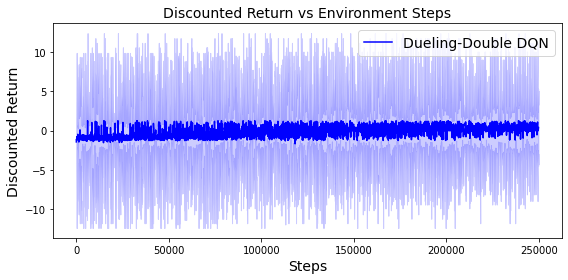

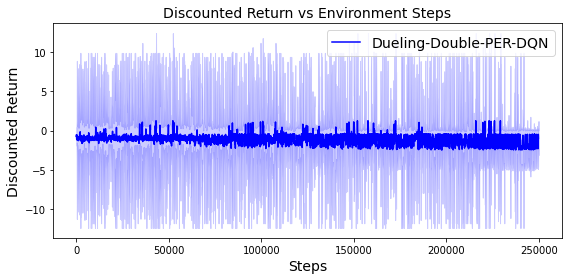

In [166]:
plt.figure(figsize=(8, 4))
    
means = returns.mean(axis=1)
y_std = np.std(returns, axis=1)
x_values = np.arange(len(means))* steps_each

plt.plot(x_values, means, label=label_plot, c="b")
plt.fill_between(x_values, y2=means + y_std, y1=means - y_std, color="b", alpha=0.2)


plt.xlabel("Steps", fontsize=14)
plt.ylabel("Discounted Return", fontsize=14)
plt.title("Discounted Return vs Environment Steps", fontsize=14)
plt.legend(fontsize=14)


means = returns.mean(axis=1)
y_std = np.std(returns, axis=1)
x_values = np.arange(len(means))* steps_each

plt.plot(x_values, means, label=label_plot, c="b")
plt.fill_between(x_values, y2=means + y_std, y1=means - y_std, color="b", alpha=0.2)


plt.xlabel("Steps", fontsize=14)
plt.ylabel("Discounted Return", fontsize=14)
plt.title("Discounted Return vs Environment Steps", fontsize=14)
plt.legend(fontsize=14)


means = returns.mean(axis=1)
y_std = np.std(returns, axis=1)
x_values = np.arange(len(means))* steps_each

plt.plot(x_values, means, label=label_plot, c="b")
plt.fill_between(x_values, y2=means + y_std, y1=means - y_std, color="b", alpha=0.2)


plt.xlabel("Steps", fontsize=14)
plt.ylabel("Discounted Return", fontsize=14)
plt.title("Discounted Return vs Environment Steps", fontsize=14)
plt.legend(fontsize=14)





plt.tight_layout()

DQN vs Double DQN

In [170]:
len(rewards_0.reshape(-1))

400000

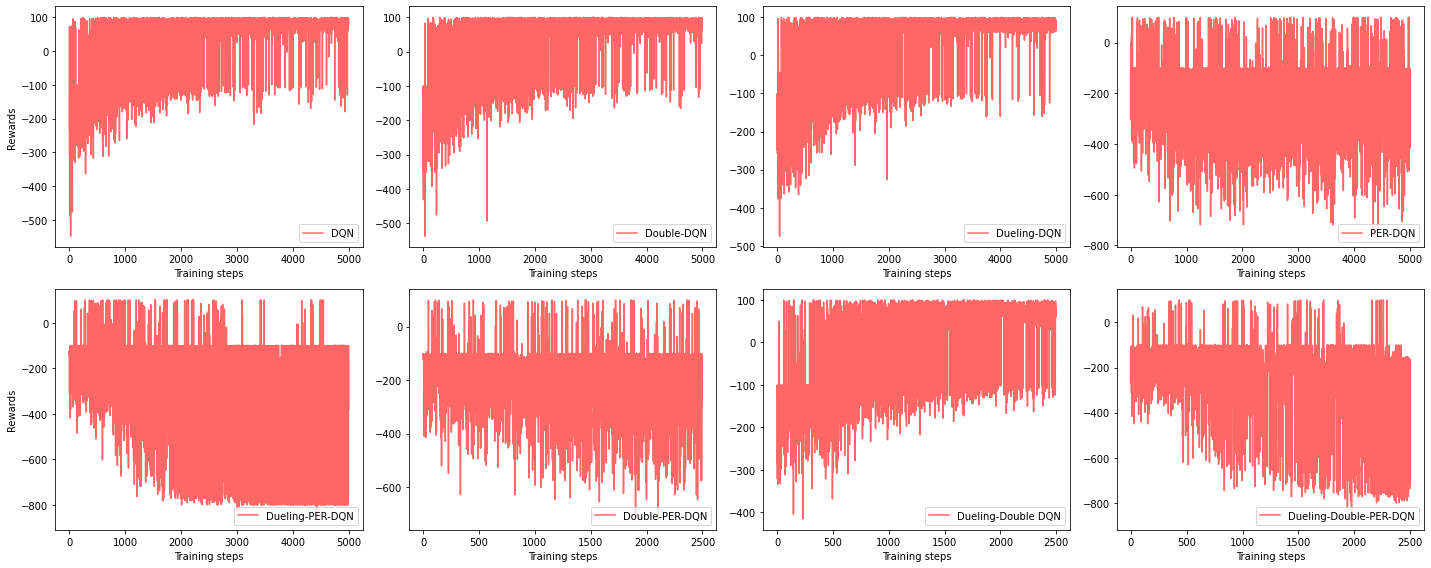

In [175]:
fig, axs = plt.subplots(2, 4, figsize=(20,8))

# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['avg'], linewidth=3, label="Average")
# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['max'], label="Max")
# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['min'], label="Min")

axs[0, 0].plot(np.arange(len(rewards_total_0)),rewards_total_0,color='r',label=labeldqn[0],alpha=0.6)
axs[0, 0].set_xlabel('Training steps')
axs[0, 0].set_ylabel('Rewards')
axs[0, 0].legend(loc=4)
axs[0, 1].plot(np.arange(len(rewards_total_1)),rewards_total_1,color='r',label=labeldqn[1],alpha=0.6)
axs[0, 1].set_xlabel('Training steps')
axs[0, 1].legend(loc=4)
axs[0, 2].plot(np.arange(len(rewards_total_2)),rewards_total_2,color='r',label=labeldqn[2],alpha=0.6)
axs[0, 2].set_xlabel('Training steps')
axs[0, 2].legend(loc=4)
axs[0, 3].plot(np.arange(len(rewards_total_3)),rewards_total_3,color='r',label=labeldqn[3],alpha=0.6)
axs[0, 3].set_xlabel('Training steps')
axs[0, 3].legend(loc=4)

axs[1, 0].plot(np.arange(len(rewards_total_4)),rewards_total_4,color='r',label=labeldqn[4],alpha=0.6)
axs[1, 0].set_xlabel('Training steps')
axs[1, 0].set_ylabel('Rewards')
axs[1, 0].legend(loc=4)
axs[1, 1].plot(np.arange(len(rewards_total_5)),rewards_total_5,color='r',label=labeldqn[5],alpha=0.6)
axs[1, 1].set_xlabel('Training steps')
axs[1, 1].legend(loc=4)
axs[1, 2].plot(np.arange(len(rewards_total_6)),rewards_total_6,color='r',label=labeldqn[6],alpha=0.6)
axs[1, 2].set_xlabel('Training steps')
axs[1, 2].legend(loc=4)
axs[1, 3].plot(np.arange(len(rewards_total_7)),rewards_total_7,color='r',label=labeldqn[7],alpha=0.6)
axs[1, 3].set_xlabel('Training steps')
axs[1, 3].legend(loc=4)

plt.tight_layout()
plt.show()

In [ ]:
abl.append([False, False, False])  "DQN"
abl.append([True, False, False])  "Double-DQN"
abl.append([False, True, False]) "Dueling-DQN"
abl.append([False, False, True]) "PER-DQN"
abl.append([False, True, True]) "Dueling-PER-DQN"
abl.append([True, False, True]) "Double-PER-DQN"
abl.append([True, True, False]) "Dueling-Double DQN"
abl.append([True, True, True]) "Dueling-Double-PER-DQN"

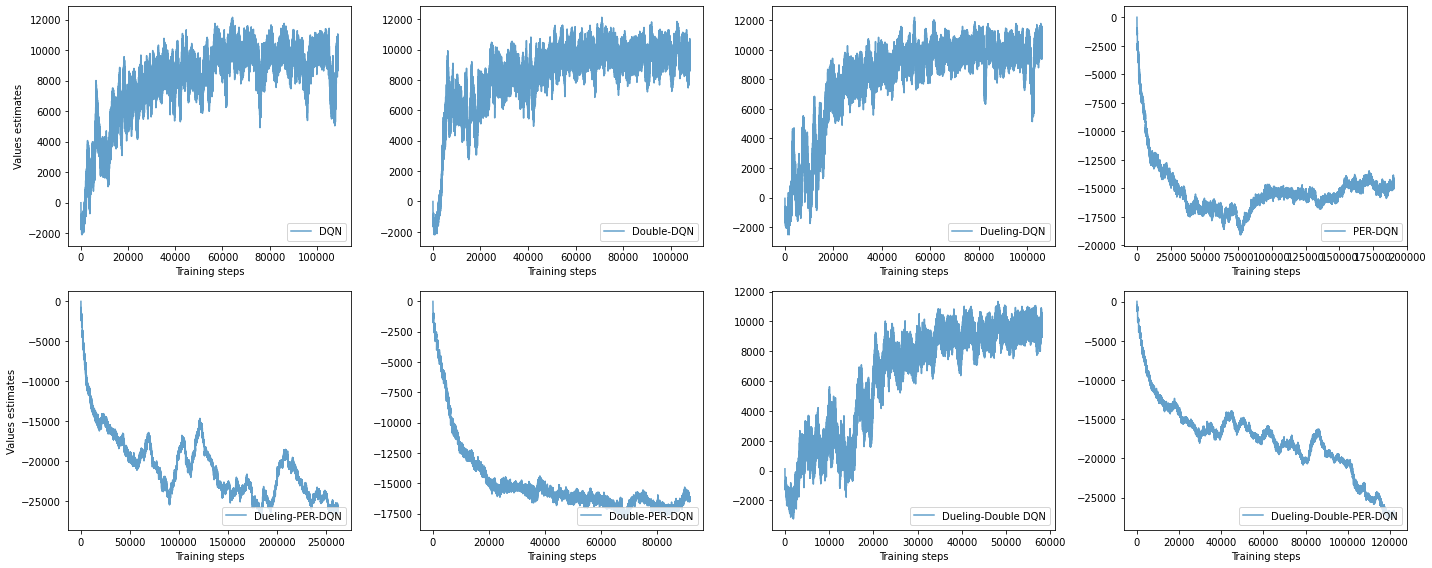

In [169]:
fig, axs = plt.subplots(2, 4, figsize=(20,8))

# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['avg'], linewidth=3, label="Average")
# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['max'], label="Max")
# axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['min'], label="Min")

axs[0, 0].plot(np.arange(len(qvalues_estimates_0[0])),qvalues_estimates_0[0],label=labeldqn[0],alpha=0.7)
axs[0, 0].set_xlabel('Training steps')
axs[0, 0].set_ylabel('Values estimates')
axs[0, 0].legend(loc=4)
axs[0, 1].plot(np.arange(len(qvalues_estimates_1[0])),qvalues_estimates_1[0],label=labeldqn[1],alpha=0.7)
axs[0, 1].set_xlabel('Training steps')
axs[0, 1].legend(loc=4)
axs[0, 2].plot(np.arange(len(qvalues_estimates_2[0])),qvalues_estimates_2[0],label=labeldqn[2],alpha=0.7)
axs[0, 2].set_xlabel('Training steps')
axs[0, 2].legend(loc=4)
axs[0, 3].plot(np.arange(len(qvalues_estimates_3[0])),qvalues_estimates_3[0],label=labeldqn[3],alpha=0.7)
axs[0, 3].set_xlabel('Training steps')
axs[0, 3].legend(loc=4)

axs[1, 0].plot(np.arange(len(qvalues_estimates_4[0])),qvalues_estimates_4[0],label=labeldqn[4],alpha=0.7)
axs[1, 0].set_xlabel('Training steps')
axs[1, 0].set_ylabel('Values estimates')
axs[1, 0].legend(loc=4)
axs[1, 1].plot(np.arange(len(qvalues_estimates_5[0])),qvalues_estimates_5[0],label=labeldqn[5],alpha=0.7)
axs[1, 1].set_xlabel('Training steps')
axs[1, 1].legend(loc=4)
axs[1, 2].plot(np.arange(len(qvalues_estimates_6[0])),qvalues_estimates_6[0],label=labeldqn[6],alpha=0.7)
axs[1, 2].set_xlabel('Training steps')
axs[1, 2].legend(loc=4)
axs[1, 3].plot(np.arange(len(qvalues_estimates_7[0])),qvalues_estimates_7[0],label=labeldqn[7],alpha=0.7)
axs[1, 3].set_xlabel('Training steps')
axs[1, 3].legend(loc=4)

plt.tight_layout()
plt.show()

In [ ]:
# using the variable axs for multiple Axes
fig, axs = plt.subplots(2, 3, figsize=(16,8))

axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['avg'], linewidth=3, label="Average")
axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['max'], label="Max")
axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['min'], label="Min")
axs[0, 0].legend(loc="upper left")
axs[0, 0].set_title('Avg/Max/Min Rewards (Epsilon Greedy policy)')
axs[0, 0].set_xlabel('Episodes')
axs[0, 0].set_ylabel('Rewards')
axs[0, 0].grid(True)
#plt.show()

axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['avg'], linewidth=3, label="Average")
axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['max'], label="Max")
axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['min'], label="Min")
axs[0, 1].legend(loc="upper left")
axs[0, 1].set_title('Avg/Max/Min Rewards (Epsilon Greedy Decay policy)')
axs[0, 1].set_xlabel('Episodes')
axs[0, 1].set_ylabel('Rewards')
axs[0, 1].grid(True)
#plt.show()

axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['avg'], linewidth=3, label="Average")
axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['max'], label="Max")
axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['min'], label="Min")
axs[0, 2].legend(loc="upper left")
axs[0, 2].set_title('Avg/Max/Min Rewards (Softmax policy)')
axs[0, 2].set_xlabel('Episodes')
axs[0, 2].set_ylabel('Rewards')
plt.grid(True)
#plt.show()

axs[1, 0].plot(all_rewards_p1)
axs[1, 0].set_title('Cumulative Rewards (Epsilon Greedy policy)')
axs[1, 0].set_xlabel('Episodes')
axs[1, 0].set_ylabel('Cumulative Rewards')
axs[1, 0].grid(True)
#plt.show()

axs[1, 1].plot(all_rewards_p2)
axs[1, 1].set_title('Cumulative Rewards (Epsilon Greedy Decay policy)')
axs[1, 1].set_xlabel('Episodes')
axs[1, 1].set_ylabel('Cumulative Rewards')
axs[1, 1].grid(True)
#plt.show()

axs[1, 2].plot(all_rewards_p3)
axs[1, 2].set_title('Cumulative Rewards (Softmax policy)')
axs[1, 2].set_xlabel('Episodes')
axs[1, 2].set_ylabel('Cumulative Rewards')
axs[1, 2].grid(True)
#plt.show()

fig.tight_layout()
plt.show()

## Evaluate model

In [ ]:
env_i = MapWalkingEnv(10,10)
len(env_i.displ_board.reshape(-1))

400

In [11]:
import copy
def eval_model(model, mode='static', display=True, envtype='easy'):
    i = 0
    if envtype == 'easy':
        eval_env = MapWalkingEnv(6,6) #mode=mode)
    else:
        eval_env = MapWalkingEnv(10,10) #mode=mode)
    
    device = torch.device('cpu')
    if torch.cuda.is_available():
        device = torch.device('cuda')

    state = eval_env.reset()
    #print(state)
    
    state_decoded = eval_env.decode_grid(state) + np.random.rand(1,400)/100.0

    state_decoded = torch.from_numpy(state_decoded).float().to(device)
    #previous_obs = copy.copy(state_decoded)
    #print(state_decoded)
    if display:
        print("Initial State:")
        print(eval_env.display())
    status = 1
    cum_reward = 0
    reward_win = 0
    reward_loss = 0
    state_visited = 0
    gamma = 0.95
    disc_return=0
    #reward = 0
    while(status == 1):  
        #valid_actions = eval_env.valid_actions()
        qval = model(state_decoded)
        qval_ = qval.data.cpu().numpy()
        action = np.argmax(qval_)
        #print(action, eval_env.P[eval_env.s])
        #action = action_set[action_]
        
        if display:
            print('Move #: %s; Taking action: %s' % (i, action))

        
        next_state, reward, terminal, _ = eval_env.step(action)
        state_decoded = eval_env.decode_grid(next_state) + np.random.rand(1,400)/100.0
        state_decoded = torch.from_numpy(state_decoded).float().to(device)
        
        #print(eval_env.decode_grid(state)[7],eval_env.decode_grid(next_state)[7])
        
        if display:
            print(eval_env.display())
            
        cum_reward += reward 
        
        disc_return = disc_return + (reward*pow(gamma,i))
        state_visited+=1
        #terminal_reward = eval_env.eval_reward()
        
        if terminal == 1:
            if reward > 0:
                status = 2
                reward_win = cum_reward
                reward_loss = -np.inf
                if display:
                    print("Game won! Reward: %s" % (cum_reward,))
            else:
                status = 0
                reward_loss = cum_reward
                reward_win = -np.inf
                if display:
                    print("Game lost. Reward: %s" % (cum_reward,))
        i += 1
        if (i > 400):
            if display:
                print("Game lost; too many moves.")
            break
    
    win = True if status == 2 else False
    return win, cum_reward, reward_win, reward_loss, state_visited, disc_return

### Evaluate model playing 1000 games

In [ ]:
reward*pow(gamma,2)

In [26]:
max_games = 1000
wins = 0
cum_rewards = []
rewards_win = []
rewards_loss = []
states_visited_1 = []
disc_returns_1 = []
for i in range(max_games):
    win, cum_reward, reward_win, reward_loss, state_visited, disc_return = eval_model(model_3, mode='static', display=False, envtype='hard')
    if win:
        wins += 1
    cum_rewards.append(cum_reward)
    rewards_win.append(reward_win)
    rewards_loss.append(reward_loss)
    states_visited_1.append(state_visited)
    disc_returns_1.append(disc_return)

win_perc = float(wins) / float(max_games)
print("Games played: {0}, # of wins: {1}".format(max_games,wins))
print("Win percentage: {}%".format(100.0*win_perc))

Games played: 1000, # of wins: 0
Win percentage: 0.0%


In [ ]:
max_games = 1000
wins = 0
cum_rewards = []
rewards_win = []
rewards_loss = []
states_visited_1 = []
disc_returns_1 = []
for i in range(max_games):
    win, cum_reward, reward_win, reward_loss, state_visited, disc_return = eval_model(model_0, mode='static', display=False, envtype='hard')
    if win:
        wins += 1
    cum_rewards.append(cum_reward)
    rewards_win.append(reward_win)
    rewards_loss.append(reward_loss)
    states_visited_1.append(state_visited)
    disc_returns_1.append(disc_return)

win_perc = float(wins) / float(max_games)
print("Games played: {0}, # of wins: {1}".format(max_games,wins))
print("Win percentage: {}%".format(100.0*win_perc))

### Evaluate with display one episode only

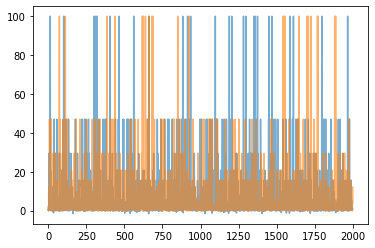

In [95]:
plt.plot(np.arange(len(disc_returns_0)), [i / j for i, j in zip(disc_returns_0, states_visited_0)], alpha=0.6)
plt.plot(np.arange(len(disc_returns_1)), [i / j for i, j in zip(disc_returns_1, states_visited_1)], alpha=0.6)

In [10]:
max_games = 1000
wins = 0
cum_rewards = []
rewards_win = []
rewards_loss = []
for i in range(max_games):
    win, cum_reward, reward_win, reward_loss = eval_model(model_0, mode='static', display=False, envtype='hard')
    if win:
        wins += 1
    cum_rewards.append(cum_reward)
    rewards_win.append(reward_win)
    rewards_loss.append(reward_loss)
    
win_perc = float(wins) / float(max_games)
print("Games played: {0}, # of wins: {1}".format(max_games,wins))
print("Win percentage: {}%".format(100.0*win_perc))

NameError: ignored

In [ ]:
cum_rewards = []
cum_rewards.append(1)
cum_rewards.append(2)
cum_rewards.append(-np.inf)
cum_rewards.append(3)
cum_rewards.append(4)
cum_rewards

[1, 2, -inf, 3, 4]

### Cumulative rewards

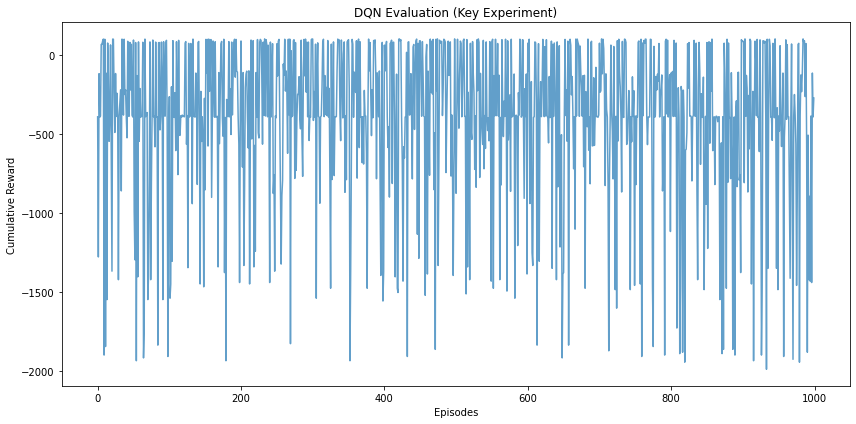

In [ ]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
ax = fig.add_subplot(111)
plt.plot(np.arange(len(cum_rewards)),cum_rewards, alpha=0.7)
plt.title('DQN Evaluation (Key Experiment)')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Reward')
plt.show()

No handles with labels found to put in legend.


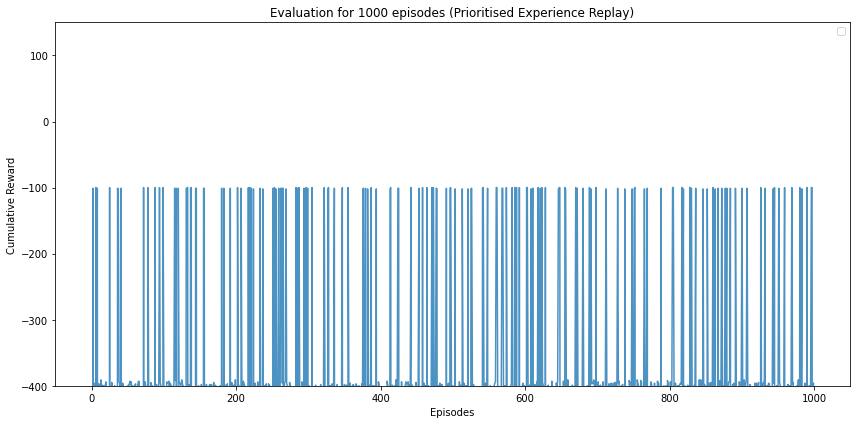

In [27]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
ax = fig.add_subplot(111)
plt.plot(np.arange(len(cum_rewards)),cum_rewards, alpha=0.8)
plt.plot(np.arange(len(rewards_win)),rewards_win, alpha=0.8)
plt.title('Evaluation for 1000 episodes (Prioritised Experience Replay)')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Reward')
plt.ylim([-400,150])
plt.legend()
plt.show()

### Wins vs. Losses

In [ ]:
len(rewards_win)

1000

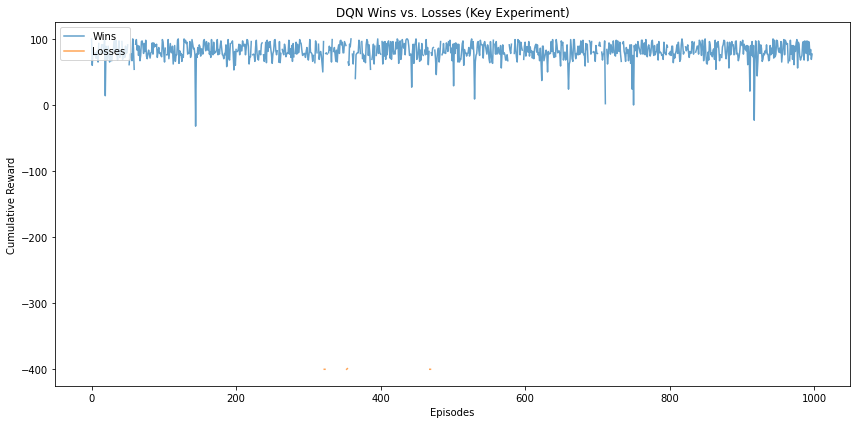

In [16]:
fig = plt.figure(figsize=(12,6),tight_layout=True)
plt.plot(np.arange(len(rewards_win)),rewards_win, alpha=0.7, label="Wins")
plt.plot(np.arange(len(rewards_loss)),rewards_loss, alpha=0.7, label="Losses")
plt.title('DQN Wins vs. Losses (Key Experiment)')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Reward')
plt.legend(loc="upper left")
plt.show()

In [ ]:
len(cum_rewards)

1000

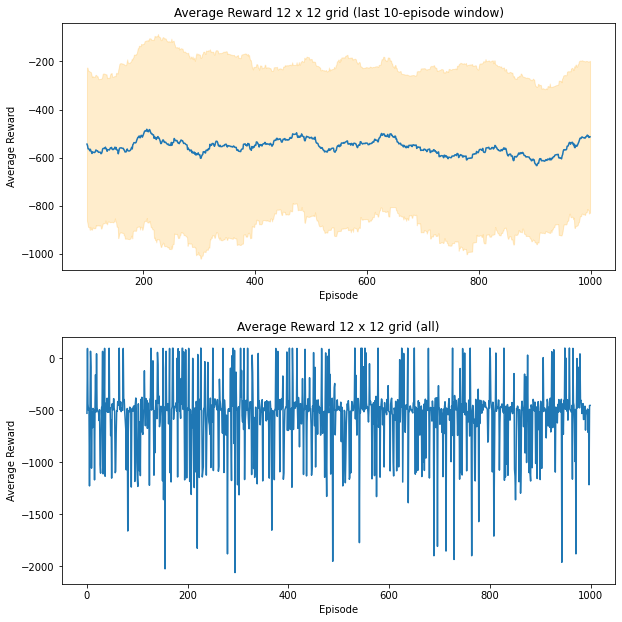

In [ ]:
reward = cum_rewards #reward['reward']

avg = 10
window = int(len(reward)/avg)
fig, ((ax1), (ax2)) = plt.subplots(2, 1, figsize=[9,9]);
rolling_mean = pd.Series(reward).rolling(window).mean()
std = pd.Series(reward).rolling(window).std()
ax1.plot(rolling_mean)
ax1.fill_between(range(len(reward)),rolling_mean-std, rolling_mean+std, color='orange', alpha=0.2)
ax1.set_title('Average Reward 12 x 12 grid (last {}-episode window)'.format(avg))
ax1.set_xlabel('Episode'); 
ax1.set_ylabel('Average Reward')

ax2.plot(reward)
ax2.set_title('Average Reward 12 x 12 grid (all)')
ax2.set_xlabel('Episode'); 
ax2.set_ylabel('Average Reward')
fig.tight_layout(pad=2)
plt.show()

In [ ]:
import time
import numpy as np
import torch
from Gridworld import Gridworld
from IPython.display import clear_output
import random
from matplotlib import pylab as plt

l1 = 64
l2 = 150
l3 = 100
l4 = 4

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2),
    torch.nn.ReLU(),
    torch.nn.Linear(l2, l3),
    torch.nn.ReLU(),
    torch.nn.Linear(l3,l4)
)
loss_fn = torch.nn.MSELoss()
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

gamma = 0.9
epsilon = 1.0
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

gamma = 0.9
epsilon = 1.0
action_set = {
    0: 'u',
    1: 'd',
    2: 'l',
    3: 'r',
}
epochs = 100
losses = [] #A
for i in range(epochs): #B
    game = Gridworld(size=4, mode='static') #C
    state_ = game.board.render_np().reshape(1,64) + np.random.rand(1,64)/10.0 #D
    state1 = torch.from_numpy(state_).float() #E
    print(state1)
    status = 1 #F
    while(status == 1): #G
        qval = model(state1) #H
        qval_ = qval.data.numpy()
        if (random.random() < epsilon): #I
            action_ = np.random.randint(0,4)
        else:
            action_ = np.argmax(qval_)
        
        action = action_set[action_] #J
        game.makeMove(action) #K
        state2_ = game.board.render_np().reshape(1,64) + np.random.rand(1,64)/10.0
        state2 = torch.from_numpy(state2_).float() #L
        reward = game.reward()
        with torch.no_grad():
            newQ = model(state2.reshape(1,64))
        maxQ = torch.max(newQ) #M
        if reward == -1: #N
            Y = reward + (gamma * maxQ)
        else:
            Y = reward
        Y = torch.Tensor([Y]).detach()
        X = qval.squeeze()[action_] #O
        loss = loss_fn(X, Y) #P
        print(i, loss.item())
        clear_output(wait=True)
        optimizer.zero_grad()
        loss.backward()
        losses.append(loss.item())
        optimizer.step()
        state1 = state2
        if reward != -1: #Q
            status = 0
    if epsilon > 0.1: #R
        epsilon -= (1/epochs)

tensor([[6.4053e-02, 6.4667e-02, 2.0937e-02, 7.7761e-02, 7.2166e-02, 5.7542e-02,
         6.0811e-02, 3.5169e-02, 7.7682e-02, 1.0689e+00, 8.4419e-03, 4.5977e-02,
         2.1352e-02, 9.9922e-02, 9.6366e-03, 2.4422e-02, 1.0773e+00, 2.7192e-02,
         8.2992e-02, 1.8774e-02, 6.3068e-02, 5.6682e-02, 4.9645e-02, 5.9536e-03,
         6.1633e-02, 5.6128e-02, 3.8569e-03, 9.3630e-02, 1.9067e-02, 2.8323e-02,
         1.4681e-02, 3.5632e-02, 6.5988e-02, 1.0644e+00, 9.3140e-02, 1.1554e-02,
         8.2083e-02, 7.2564e-02, 8.2287e-02, 6.7291e-02, 4.0643e-02, 3.7956e-02,
         2.3162e-02, 8.6461e-02, 8.3063e-04, 1.1151e-02, 9.7704e-02, 5.5965e-02,
         5.9143e-02, 5.3655e-02, 5.4331e-02, 9.1325e-02, 6.6616e-02, 1.0114e+00,
         8.9459e-02, 2.0997e-02, 3.2782e-02, 8.3223e-02, 6.9424e-02, 7.7123e-02,
         2.1463e-02, 5.2673e-02, 1.1903e-02, 5.2532e-02]])


KeyboardInterrupt: 

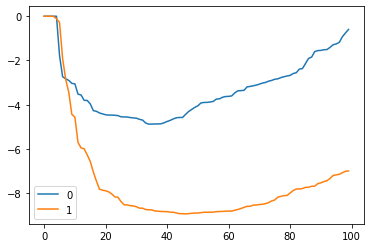

In [ ]:
plt.plot(qvalues_estimates_total_0,label='0')
plt.plot(qvalues_estimates_total_1,label='1')
plt.legend()
#qvalues_estimates_total_1